# PetFinder.my: предсказание скорости пристройства животных из приютов

# 0. Описание задачи

[PetFinder.my](https://www.petfinder.my/) — малайзийский сайт, где приюты, волонтёры и обычные люди размещают объявления о бездомных собаках и кошках, чтобы найти им хозяев. Данные взяты из соревнования Kaggle [PetFinder.my Adoption Prediction](https://www.kaggle.com/c/petfinder-adoption-prediction). Каждая строка — одно объявление: вид животного, возраст, порода, пол, окрас, размер, шерсть, прививки, стерилизация, здоровье, плата, штат, число фото и видео и текстовое описание.

Нужно предсказать `AdoptionSpeed`, т.е. как быстро животное нашло хозяев:

| Класс | Смысл |
|---|---|
| 0 | пристроили в тот же день, когда разместили объявление |
| 1 | за 1–7 дней (первая неделя) |
| 2 | за 8–30 дней (первый месяц) |
| 3 | за 31–90 дней (второй и третий месяц) |
| 4 | не пристроили за 100 дней |

Это задача многоклассовой классификации с 5 классами. Классы упорядочены: перепутать 3 и 4 лучше, чем 0 и 4. Поэтому кроме доли правильных ответов будем считать квадратичную взвешенную каппу, это метрика соревнования, которая учитывает порядок классов.

Смысл задачи: если заранее знать, какие объявления долго не найдут хозяев, приют может их улучшить (добавить фото, переписать описание, снизить плату). Ещё хочется понять, что вообще влияет на скорость пристройства.

## Описание признаков

| Признак | Описание | Тип |
|---|---|---|
| `Type` | вид: 1 — собака, 2 — кошка | категориальный (бинарный) |
| `Name` | кличка | строка (почти номинальный) |
| `Age` | возраст в месяцах | количественный |
| `Breed1` | основная порода (код) | категориальный |
| `Breed2` | вторая порода, если метис (0 — нет) | категориальный |
| `Gender` | пол: 1 — самец, 2 — самка, 3 — смешанная группа | категориальный |
| `Color1`, `Color2`, `Color3` | окрасы (коды 1–7; 0 — нет) | категориальные |
| `MaturitySize` | размер взрослого животного: 1 — маленький … 4 — очень большой | порядковый |
| `FurLength` | длина шерсти: 1 — короткая, 2 — средняя, 3 — длинная | порядковый |
| `Vaccinated` | привит: 1 — да, 2 — нет, 3 — не уверены | категориальный |
| `Dewormed` | обработан от глистов: 1 — да, 2 — нет, 3 — не уверены | категориальный |
| `Sterilized` | стерилизован: 1 — да, 2 — нет, 3 — не уверены | категориальный |
| `Health` | здоровье: 1 — здоров, 2 — небольшая травма/болезнь, 3 — серьёзная | порядковый |
| `Quantity` | сколько животных в объявлении | количественный |
| `Fee` | плата за пристройство (малайзийские ринггиты, 0 — бесплатно) | количественный |
| `State` | штат Малайзии (код) | категориальный |
| `RescuerID` | идентификатор того, кто разместил объявление | идентификатор |
| `VideoAmt` | количество видео | количественный |
| `PhotoAmt` | количество фотографий | количественный |
| `Description` | свободное текстовое описание животного | текстовый |
| `PetID` | идентификатор объявления | идентификатор |
| `AdoptionSpeed` | скорость пристройства (0–4) | целевой (порядковый) |

Породы, окрасы и штаты в данных записаны кодами.

# 1. Чтение данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

In [2]:
data_raw = pd.read_csv('train.csv')
data_raw.shape

(14993, 24)

В таблице 14 993 объявления и 24 столбца: 21 признак, 2 идентификатора (`PetID`, `RescuerID`) и целевой `AdoptionSpeed`.

In [3]:
data_raw.head()

,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,FurLength,Vaccinated,Dewormed,Sterilized,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,1,2,2,2,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,2,3,3,3,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,2,1,1,2,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,1,1,1,2,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,1,2,2,2,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2


In [4]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Type           14993 non-null  int64  
 1   Name           13728 non-null  str    
 2   Age            14993 non-null  int64  
 3   Breed1         14993 non-null  int64  
 4   Breed2         14993 non-null  int64  
 5   Gender         14993 non-null  int64  
 6   Color1         14993 non-null  int64  
 7   Color2         14993 non-null  int64  
 8   Color3         14993 non-null  int64  
 9   MaturitySize   14993 non-null  int64  
 10  FurLength      14993 non-null  int64  
 11  Vaccinated     14993 non-null  int64  
 12  Dewormed       14993 non-null  int64  
 13  Sterilized     14993 non-null  int64  
 14  Health         14993 non-null  int64  
 15  Quantity       14993 non-null  int64  
 16  Fee            14993 non-null  int64  
 17  State          14993 non-null  int64  
 18  RescuerID      14

Все столбцы, кроме `Name`, `RescuerID`, `Description` и `PetID`, pandas прочитал как числа. Но многие из них на самом деле коды категорий (порода, окрас, штат), и складывать или сравнивать их нельзя. Типы поправим дальше.

## Пропущенные значения

In [5]:
data_raw.isnull().sum()

Type                0
Name             1265
Age                 0
Breed1              0
Breed2              0
Gender              0
Color1              0
Color2              0
Color3              0
MaturitySize        0
FurLength           0
Vaccinated          0
Dewormed            0
Sterilized          0
Health              0
Quantity            0
Fee                 0
State               0
RescuerID           0
VideoAmt            0
Description        13
PetID               0
PhotoAmt            0
AdoptionSpeed       0
dtype: int64

In [6]:
print('Строк хотя бы с одним пропуском:', data_raw.isnull().any(axis=1).sum(),
      f'({data_raw.isnull().any(axis=1).mean():.1%})')

Строк хотя бы с одним пропуском: 1277 (8.5%)


Пропуски есть только в `Name` (1265 объявлений без клички) и `Description` (13 без описания). Ими займёмся в пункте 5.

## Целевой признак

In [7]:
pd.DataFrame({'количество': data_raw['AdoptionSpeed'].value_counts().sort_index(),
              'доля': data_raw['AdoptionSpeed'].value_counts(normalize=True).sort_index().round(3)})

,количество,доля
AdoptionSpeed,,
0,410,0.027
1,3090,0.206
2,4037,0.269
3,3259,0.217
4,4197,0.280


Классы 1–4 встречаются примерно одинаково (21–28%), а класс 0 редкий, всего 2.7%.

## Удаляем идентификаторы

`PetID` у каждой строки свой, а `RescuerID` — номер автора объявления. Само животное они не описывают, поэтому удаляем их.

In [8]:
data = data_raw.drop(['PetID', 'RescuerID'], axis=1)
data.shape

(14993, 22)

## Типы признаков

- количественные (5): `Age`, `Quantity`, `Fee`, `VideoAmt`, `PhotoAmt`;
- категориальные (11): `Type`, `Breed1`, `Breed2`, `Gender`, `Color1`, `Color2`, `Color3`, `State`, `Vaccinated`, `Dewormed`, `Sterilized`;
- порядковые (3): `MaturitySize`, `FurLength`, `Health`. Их значения можно упорядочить (маленький < средний < большой), поэтому оставим их числами;
- текстовый (1): `Description`;
- строковый `Name`.

Почему `Description` считаем текстовым признаком, а `Name` и категориальные нет? У категориального признака небольшой набор значений (14 штатов, 7 окрасов, ~170 пород), каждое значение повторяется много раз, и его можно закодировать one-hot. Описание же — свободный текст из нескольких предложений, и почти все описания разные. Как категорию его не закодировать, из него нужно извлекать слова (мешок слов, TF-IDF). Кличка — короткая строка из одного-двух слов, она тоже почти всегда уникальна, но смысла в ней мало: вряд ли «Lucky» или «Mimi» влияет на пристройство. Из клички возьмём только то, есть она или нет.

In [9]:
print('Уникальных описаний:', data['Description'].nunique(), 'из', data['Description'].notnull().sum())
print('Уникальных кличек:  ', data['Name'].nunique(), 'из', data['Name'].notnull().sum())

Уникальных описаний: 14031 из 14980
Уникальных кличек:   9059 из 13728


Переведём категориальные признаки в тип `category`:

In [10]:
numerical_columns   = ['Age', 'Quantity', 'Fee', 'VideoAmt', 'PhotoAmt']
categorical_columns = ['Type', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2', 'Color3',
                       'State', 'Vaccinated', 'Dewormed', 'Sterilized']
ordinal_columns     = ['MaturitySize', 'FurLength', 'Health']

for c in categorical_columns:
    data[c] = data[c].astype('category')

data.dtypes

Type             category
Name                  str
Age                 int64
Breed1           category
Breed2           category
Gender           category
Color1           category
Color2           category
Color3           category
MaturitySize        int64
FurLength           int64
Vaccinated       category
Dewormed         category
Sterilized       category
Health              int64
Quantity            int64
Fee                 int64
State            category
VideoAmt            int64
Description           str
PhotoAmt          float64
AdoptionSpeed       int64
dtype: object

In [11]:
for c in categorical_columns:
    print(f'{c:11s} уникальных значений: {data[c].nunique()}')

Type        уникальных значений: 2
Breed1      уникальных значений: 176
Breed2      уникальных значений: 135
Gender      уникальных значений: 3
Color1      уникальных значений: 7
Color2      уникальных значений: 7
Color3      уникальных значений: 6
State       уникальных значений: 14
Vaccinated  уникальных значений: 3
Dewormed    уникальных значений: 3
Sterilized  уникальных значений: 3


У большинства категориальных признаков 2–7 значений, но у пород (`Breed1` — 176, `Breed2` — 135) и штатов (14) их много. Что делать с породами, решим в пункте 6.

# 2. Разбиение на обучающую и тестовую выборки

Разобьём данные на обучающую и тестовую выборки в пропорции 3:1. Параметр `stratify=y` сохраняет доли классов в обеих частях, это нужно из-за редкого класса 0.

Тестовая выборка играет роль новых объявлений. Поэтому всё, что нужно для обработки данных (средние и дисперсии для нормализации, квантили для выбросов, словарь TF-IDF, список частых пород), считаем только по обучающей выборке, а к тестовой просто применяем. Иначе информация из теста попадёт в модель (утечка данных, *data leakage*) и оценка на тесте получится завышенной. Графики в пункте 3 тоже строим по обучающей выборке.

In [12]:
from sklearn.model_selection import train_test_split

X = data.drop('AdoptionSpeed', axis=1)
y = data['AdoptionSpeed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print(X_train.shape, X_test.shape)

(11244, 21) (3749, 21)


In [13]:
pd.DataFrame({'train': y_train.value_counts(normalize=True).sort_index(),
              'test':  y_test.value_counts(normalize=True).sort_index()}).round(3)

,train,test
AdoptionSpeed,,
0,0.027,0.027
1,0.206,0.206
2,0.269,0.269
3,0.217,0.217
4,0.280,0.280


Доли классов в обеих выборках одинаковые.

# 3. Визуализация и основные характеристики

Соберём признаки и целевой столбец обучающей выборки в одну таблицу:

In [14]:
train = X_train.copy()
train['AdoptionSpeed'] = y_train

## Основные характеристики

In [15]:
train[numerical_columns + ordinal_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,11244.0,10.556475,18.472369,0.0,2.0,3.0,12.0,255.0
Quantity,11244.0,1.586802,1.494640,1.0,1.0,1.0,1.0,20.0
Fee,11244.0,21.096318,75.347544,0.0,0.0,0.0,0.0,2000.0
VideoAmt,11244.0,0.056919,0.343109,0.0,0.0,0.0,0.0,8.0
PhotoAmt,11244.0,3.891587,3.501627,0.0,2.0,3.0,5.0,30.0
MaturitySize,11244.0,1.861526,0.545159,1.0,2.0,2.0,2.0,4.0
FurLength,11244.0,1.469762,0.599350,1.0,1.0,1.0,2.0,3.0
Health,11244.0,1.035397,0.196906,1.0,1.0,1.0,1.0,3.0


- `Age`: среднее 10.6 месяца, медиана 3 месяца, т.е. животные в основном молодые (75% не старше года). Максимум 255 месяцев (21 год).
- `Quantity`: в 75% объявлений одно животное, максимум 20.
- `Fee`: у 75% объявлений плата 0, среднее 21 ринггит, максимум в обучающей выборке 2000.
- `VideoAmt`: видео почти ни у кого нет. `PhotoAmt`: медиана 3 фото, максимум 30.
- Порядковые: почти все животные здоровы (`Health` в среднем 1.04), размер в основном средний (`MaturitySize` = 2), шерсть чаще короткая.

У `Age`, `Fee`, `Quantity` среднее больше медианы, а максимум во много раз больше 75%-квантиля. Значит, распределения скошены и есть большие значения (см. пункт 4).

In [16]:
train.describe(include='category').T

,count,unique,top,freq
Type,11244,2,1,6144
Breed1,11244,161,307,4464
Breed2,11244,125,0,8032
Gender,11244,3,2,5428
Color1,11244,7,1,5588
Color2,11244,7,0,3359
Color3,11244,6,0,7977
Vaccinated,11244,3,2,5422
Dewormed,11244,3,1,6315
Sterilized,11244,3,2,7553


- Собак (`Type` = 1) немного больше, чем кошек: 6144 из 11 244 (55%).
- Самая частая порода `Breed1` = 307, 4464 объявления (40%). Ниже видно, что этот код бывает только у собак, видимо это метис (Mixed Breed). В обучающей выборке 161 порода из 176.
- У 71% животных нет второй породы (`Breed2` = 0).
- Чаще всего животные не привиты (`Vaccinated` = 2) и не стерилизованы (`Sterilized` = 2, 67%), но обработаны от глистов (`Dewormed` = 1).
- 58% объявлений из одного штата (код 41326).

## Целевой признак

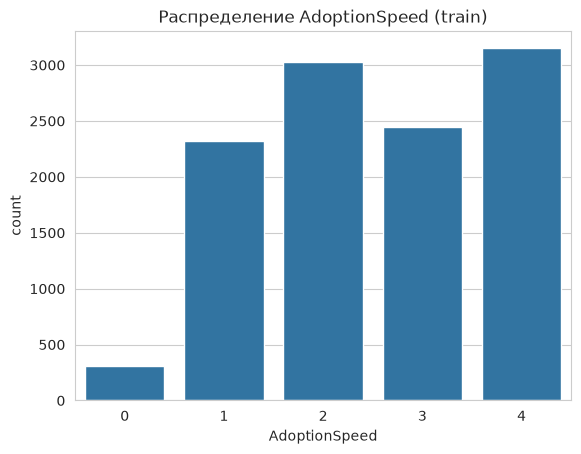

In [17]:
sns.countplot(x='AdoptionSpeed', data=train)
plt.title('Распределение AdoptionSpeed (train)')
pass

Чаще всего животных не пристраивают за 100 дней (класс 4) или пристраивают за 8–30 дней (класс 2). В тот же день пристраивают редко. Если всегда отвечать «4», угадаем ~28%, с этим и будем сравнивать модели.

## Гистограммы количественных признаков

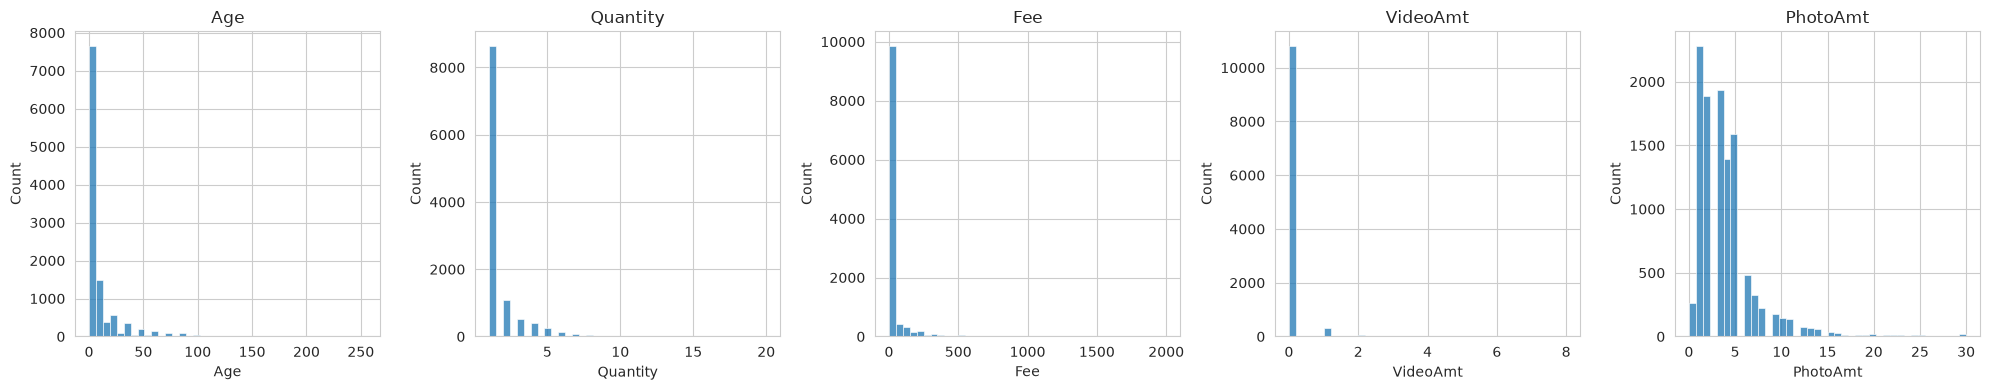

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, numerical_columns):
    sns.histplot(train[c], bins=40, ax=ax)
    ax.set_title(c)
plt.tight_layout()
pass

Все количественные признаки скошены вправо: большинство значений около нуля или единицы и есть немного больших. Почти все животные младше 2–3 лет, почти везде одно животное, нулевая плата и нет видео. Фото обычно от 1 до 5, без фото объявлений мало. Большие значения плохо влияют на kNN и линейные модели, поэтому в пункте 4 их обработаем.

## Ящики с усами

Посмотрим на количественные признаки по классам. У `Age` и `Fee` есть очень большие значения, поэтому по вертикали берём логарифмическую шкалу (прибавляем 1, чтобы не пропали нули).

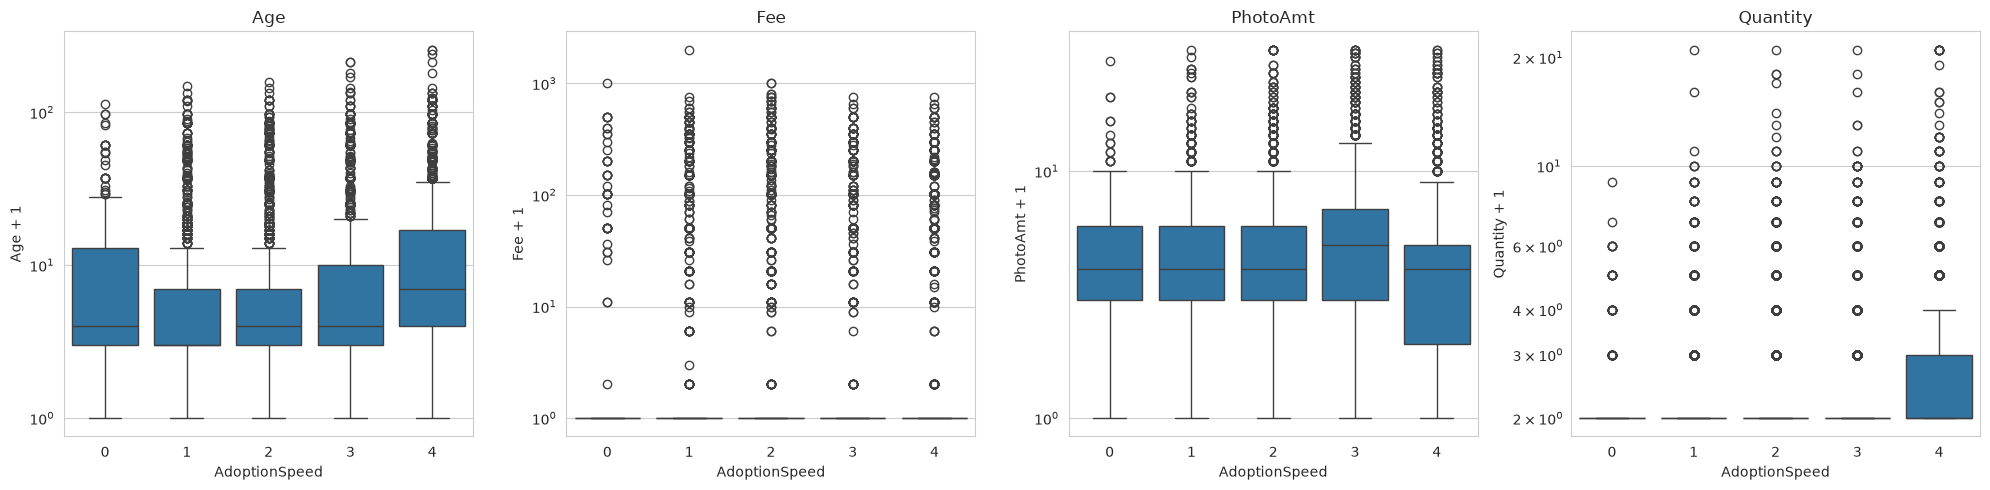

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, c in zip(axes, ['Age', 'Fee', 'PhotoAmt', 'Quantity']):
    sns.boxplot(x='AdoptionSpeed', y=train[c] + 1, data=train, ax=ax)
    ax.set_yscale('log')
    ax.set_ylabel(c + ' + 1')
    ax.set_title(c)
plt.tight_layout()
pass

In [20]:
train.groupby('AdoptionSpeed', observed=True)[numerical_columns].median()

,Age,Quantity,Fee,VideoAmt,PhotoAmt
AdoptionSpeed,,,,,
0,3.0,1.0,0.0,0.0,3.0
1,2.0,1.0,0.0,0.0,3.0
2,3.0,1.0,0.0,0.0,3.0
3,3.0,1.0,0.0,0.0,4.0
4,6.0,1.0,0.0,0.0,3.0


- Возраст: у класса 4 медиана 6 месяцев, у остальных классов 2–3 месяца. Т.е. молодых животных забирают быстрее.
- Число фото: у класса 4 нижний квартиль меньше, чем у остальных.
- `Quantity`: у класса 4 ящик выше, объявления о нескольких животных пристраиваются хуже.
- `Fee`: у всех классов медиана и квартили равны 0, разницы не видно.

В целом классы сильно перекрываются, по одному признаку их не разделить.

## Категориальные и порядковые признаки

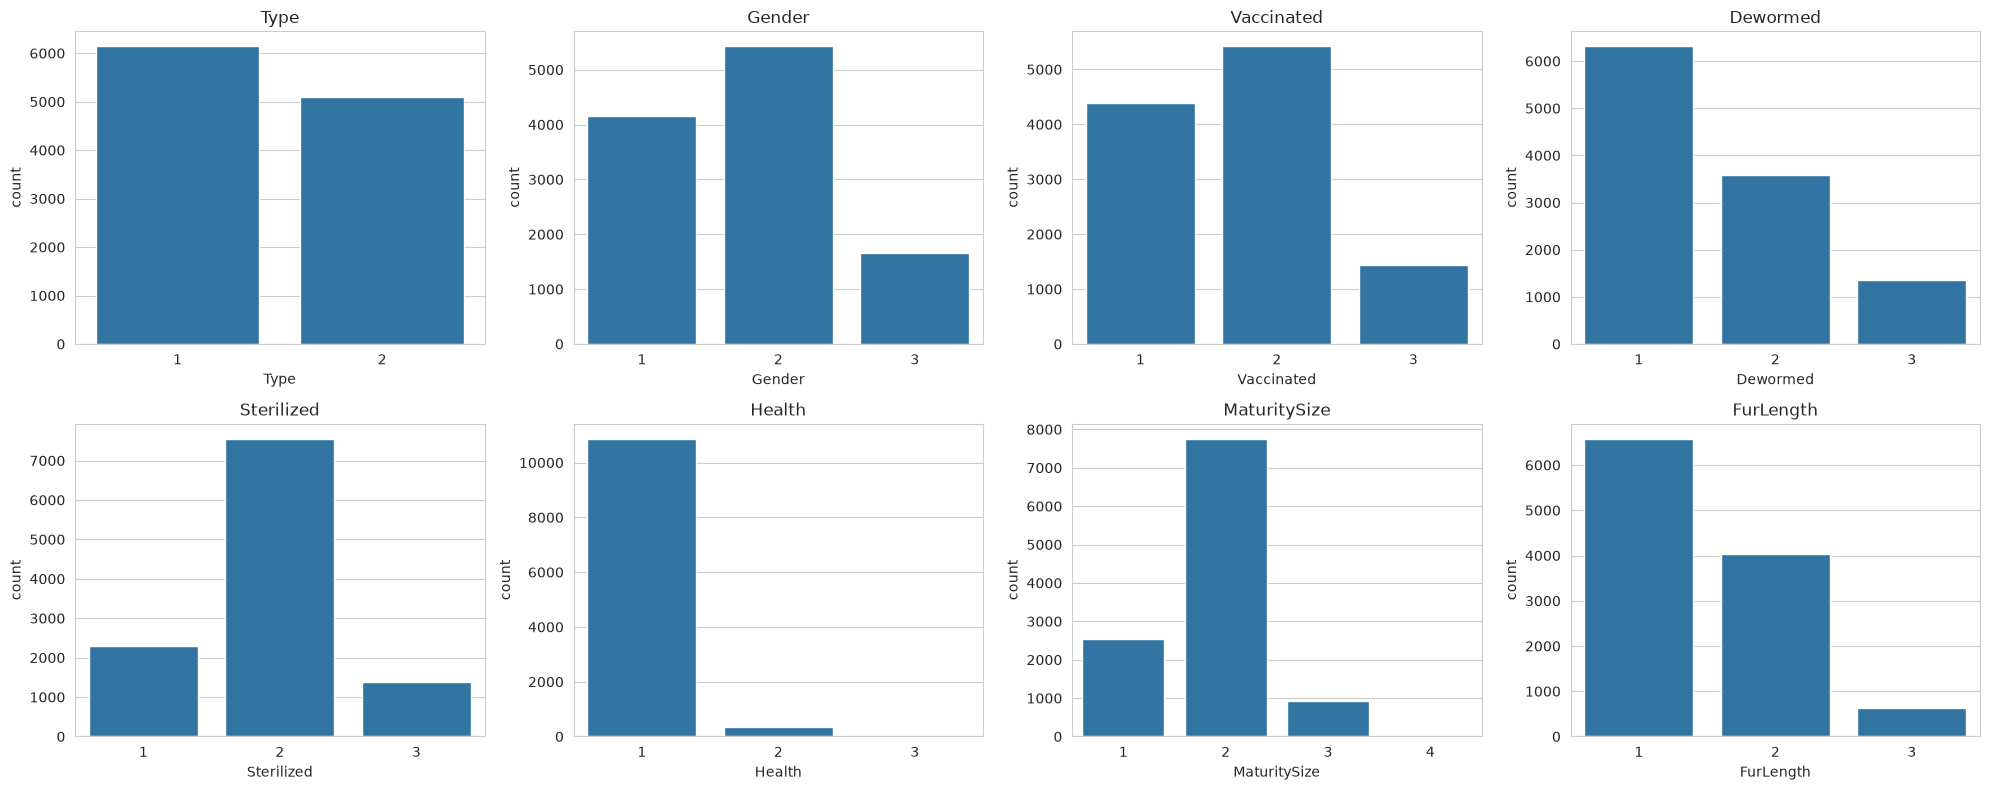

In [21]:
cols = ['Type', 'Gender', 'Vaccinated', 'Dewormed', 'Sterilized', 'Health', 'MaturitySize', 'FurLength']
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), cols):
    sns.countplot(x=c, data=train, ax=ax)
    ax.set_title(c)
plt.tight_layout()
pass

Собак немного больше, чем кошек, самок больше, чем самцов, около 15% объявлений про группы животных (`Gender` = 3). Большинство животных не привиты и не стерилизованы, но обработаны от глистов. Почти все здоровы, у большинства средний размер и короткая шерсть. `MaturitySize` = 4 и `Health` = 3 встречаются всего несколько десятков раз.

Доли классов `AdoptionSpeed` для каждого значения признака (каждая полоска в сумме 100%):

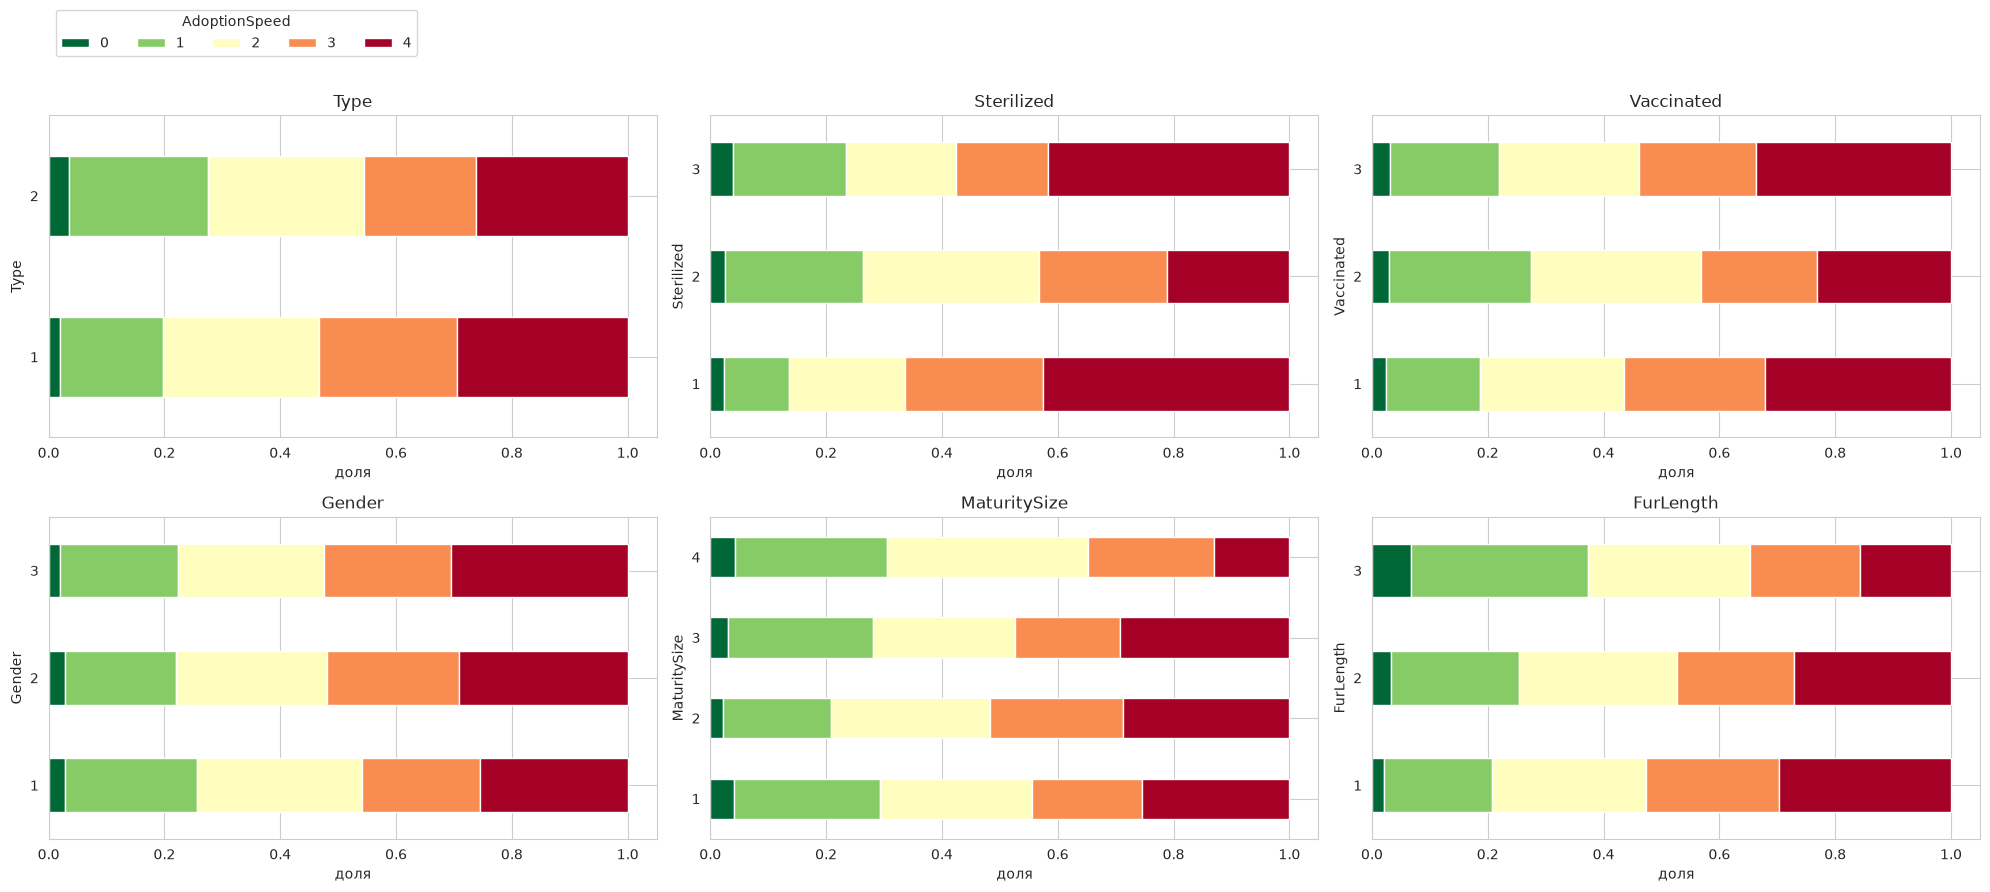

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax, c in zip(axes.ravel(), ['Type', 'Sterilized', 'Vaccinated', 'Gender', 'MaturitySize', 'FurLength']):
    pd.crosstab(train[c], train['AdoptionSpeed'], normalize='index').plot(
        kind='barh', stacked=True, ax=ax, colormap='RdYlGn_r', legend=False)
    ax.set_title(c)
    ax.set_xlabel('доля')
axes[0, 0].legend(title='AdoptionSpeed', loc='upper left', bbox_to_anchor=(0, 1.35), ncol=5)
plt.tight_layout()
pass

In [23]:
for c in ['Type', 'Sterilized', 'Vaccinated', 'Gender', 'MaturitySize', 'FurLength', 'Health']:
    print(train.groupby(c, observed=True)['AdoptionSpeed'].agg(['mean', 'count']).round(2).T, '\n')

Type         1        2
mean      2.61     2.41
count  6144.00  5100.00 

Sterilized        1        2        3
mean           2.93     2.35     2.72
count       2308.00  7553.00  1383.00 

Vaccinated        1        2        3
mean           2.68     2.36     2.62
count       4392.00  5422.00  1430.00 

Gender        1        2        3
mean       2.43     2.56     2.59
count   4156.00  5428.00  1660.00 

MaturitySize        1        2       3      4
mean             2.37     2.57    2.45   2.13
count         2534.00  7756.00  931.00  23.00 

FurLength        1        2       3
mean          2.59     2.46    2.06
count      6581.00  4044.00  619.00 

Health         1       2     3
mean        2.51    2.72   3.0
count   10872.00  346.00  26.0 



- Кошек пристраивают быстрее, чем собак: средний класс 2.41 против 2.61.
- С длинной шерстью (`FurLength` = 3) средний класс 2.06, с короткой 2.59. У длинношёрстных также самая большая доля класса 0.
- Самцов забирают немного быстрее (2.43), чем самок (2.56) и группы (2.59).
- Больных животных пристраивают медленнее (2.72 и 3.0), но их мало.
- У `MaturitySize` = 4 средний класс маленький, но там всего 23 объекта.
- Стерилизованных животных пристраивают медленнее (2.93), чем нестерилизованных (2.35), с прививками так же (2.68 против 2.36). Возможно, дело в возрасте, посмотрим на него:

In [24]:
# медианный возраст (в месяцах) в зависимости от прививок и стерилизации
pd.DataFrame({'Vaccinated': train.groupby('Vaccinated', observed=True)['Age'].median(),
              'Sterilized': train.groupby('Sterilized', observed=True)['Age'].median()})

,Vaccinated,Sterilized
1,7.0,12.0
2,2.0,2.0
3,6.0,6.0


Медианный возраст стерилизованных животных 12 месяцев, привитых 7, а нестерилизованных и непривитых 2 месяца. Котят и щенков ещё не успели привить и стерилизовать, а забирают их быстрее из-за возраста. Так что прививки и стерилизация сами по себе пристройство, скорее всего, не замедляют.

## Породы

In [25]:
top_breeds = train['Breed1'].value_counts().head(15)
print('Доля 15 самых частых пород:', round(top_breeds.sum() / len(train), 3))
pd.DataFrame({'count': top_breeds,
              'is_cat (доля кошек)': train.groupby('Breed1', observed=True)['Type'].apply(lambda s: (s == 2).mean()).loc[top_breeds.index].round(2),
              'mean AdoptionSpeed': train.groupby('Breed1', observed=True)['AdoptionSpeed'].mean().loc[top_breeds.index].round(2)})

Доля 15 самых частых пород: 0.874


,count,is_cat (доля кошек),mean AdoptionSpeed
Breed1,,,
307,4464,0.00,2.74
266,2728,1.00,2.50
265,916,1.00,2.35
299,261,1.00,2.36
264,220,1.00,2.10
292,180,1.00,2.02
285,170,1.00,1.85
141,157,0.00,2.41
205,148,0.01,2.01


15 самых частых пород покрывают 87% объявлений. Код 307 бывает только у собак, это самая частая порода и самая медленная из частых (средний класс 2.74), видимо, это беспородные собаки. Коды 264–266 и 299 бывают только у кошек. Породистых животных (например, 285 у кошек, 179, 205, 109 у собак) пристраивают быстрее, средний класс около 2.

## Плата и фотографии

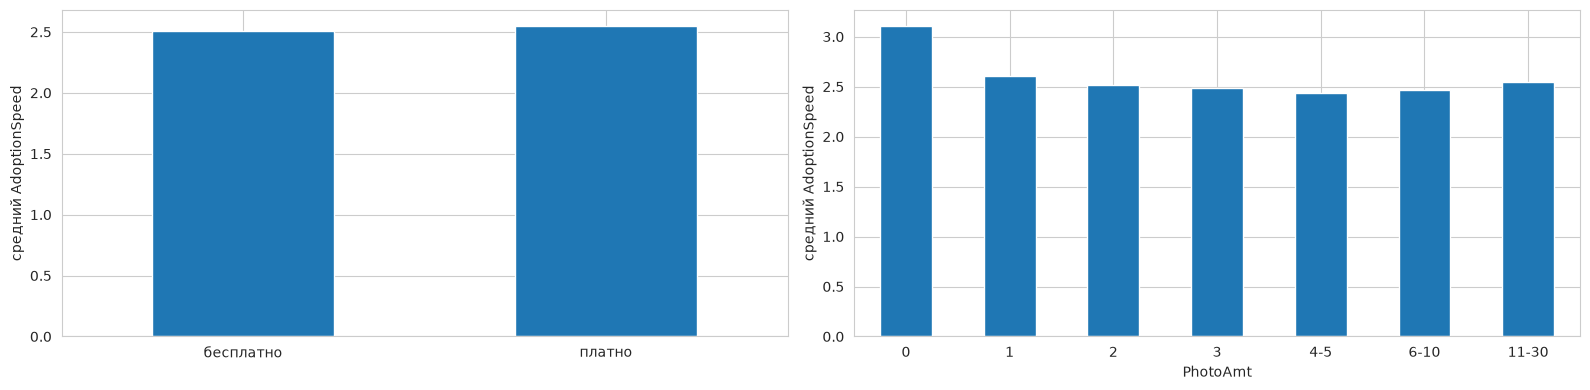

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
train.groupby(train['Fee'] > 0)['AdoptionSpeed'].mean().plot(kind='bar', ax=axes[0])
axes[0].set_xticklabels(['бесплатно', 'платно'], rotation=0)
axes[0].set_xlabel('')
axes[0].set_ylabel('средний AdoptionSpeed')
photo_bins = pd.cut(train['PhotoAmt'], [-1, 0, 1, 2, 3, 5, 10, 30], labels=['0', '1', '2', '3', '4-5', '6-10', '11-30'])
train.groupby(photo_bins, observed=True)['AdoptionSpeed'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_xlabel('PhotoAmt')
axes[1].set_ylabel('средний AdoptionSpeed')
plt.setp(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout()
pass

In [27]:
print(train.groupby(train['Fee'] > 0)['AdoptionSpeed'].agg(['mean', 'count']).round(2), '\n')
print(train.groupby(photo_bins, observed=True)['AdoptionSpeed'].agg(['mean', 'count']).round(2))

       mean  count
Fee               
False  2.51   9489
True   2.55   1755 

          mean  count
PhotoAmt             
0         3.11    261
1         2.61   2281
2         2.51   1885
3         2.49   1932
4-5       2.44   2983
6-10      2.47   1355
11-30     2.54    547


- Плата почти не влияет: средний класс 2.51 у бесплатных объявлений и 2.55 у платных.
- Без фото (261 объявление) средний класс 3.11. С одним фото уже 2.61, лучше всего с 4–5 фото (2.44), дальше лучше не становится.

## Диаграммы рассеивания

Матрица диаграмм рассеивания для количественных признаков на случайных 2000 объектах:

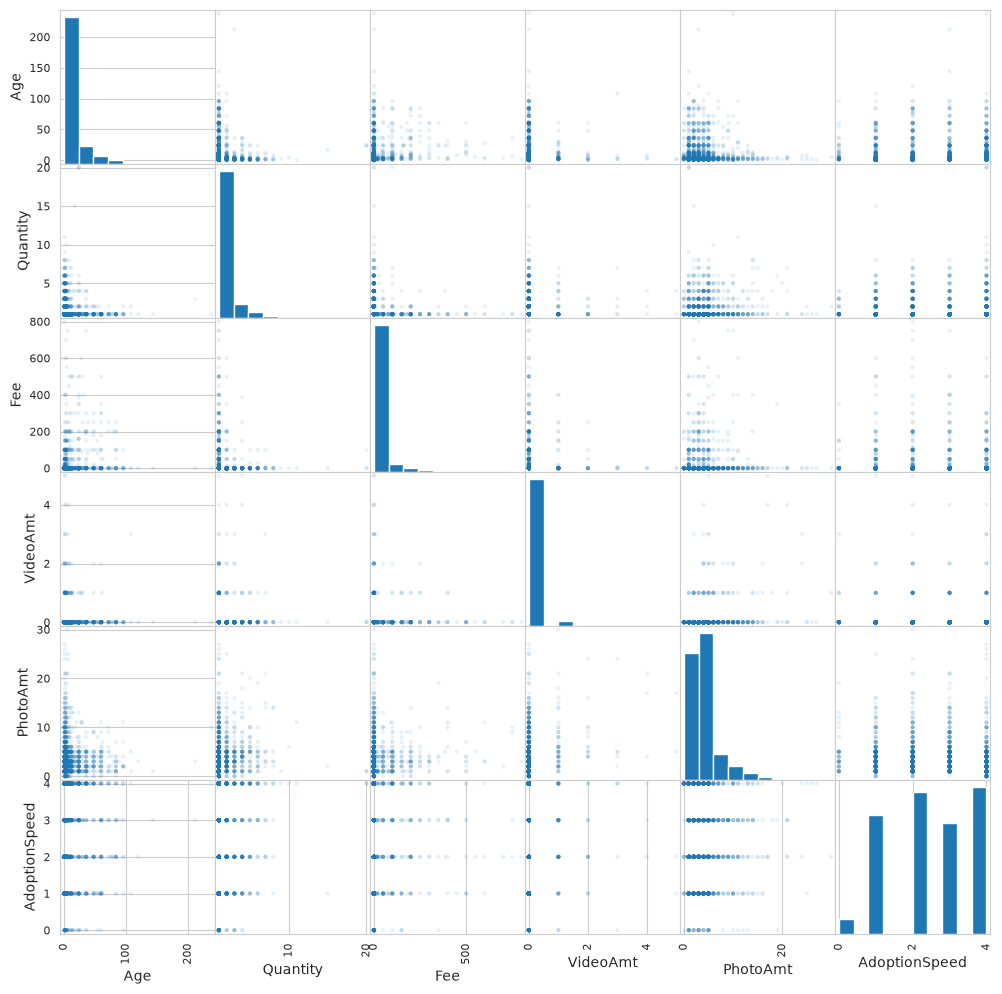

In [28]:
from pandas.plotting import scatter_matrix

sample = train.sample(2000, random_state=RANDOM_STATE)
scatter_matrix(sample[numerical_columns + ['AdoptionSpeed']], alpha=0.1, figsize=(12, 12))
pass

Явных зависимостей между количественными признаками нет, и классы не разделяются: в каждом классе есть животные любого возраста, с любой платой и любым числом фото. Признаки дискретные, поэтому точки выстраиваются в столбики.

## Корреляционная матрица

Посчитаем корреляцию для количественных и порядковых признаков и целевого. Добавим ещё `Type`, `Vaccinated`, `Dewormed`, `Sterilized`. Они закодированы как 1 — да, 2 — нет, 3 — не уверены, т.е. примерно по порядку, так что корреляция для них имеет приблизительный смысл.

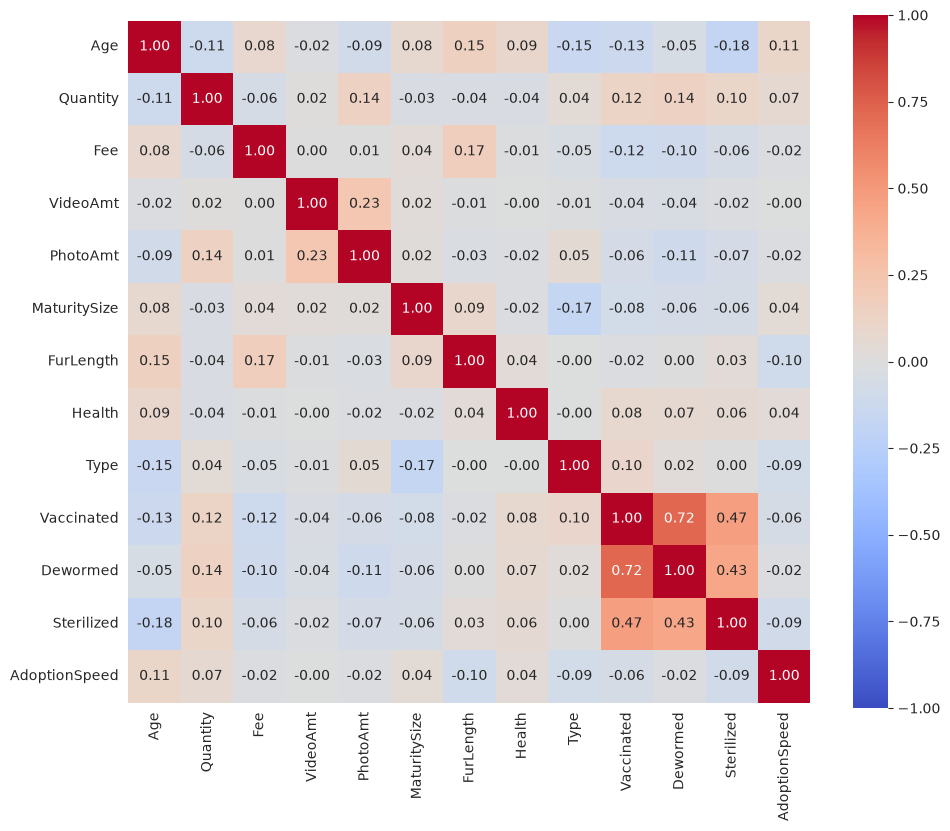

In [29]:
corr_cols = numerical_columns + ordinal_columns + ['Type', 'Vaccinated', 'Dewormed', 'Sterilized', 'AdoptionSpeed']
corr_mat = train[corr_cols].astype(float).corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
pass

In [30]:
corr_mat['AdoptionSpeed'].drop('AdoptionSpeed').sort_values()

FurLength      -0.100203
Sterilized     -0.089693
Type           -0.085719
Vaccinated     -0.061576
PhotoAmt       -0.023179
Dewormed       -0.019971
Fee            -0.018295
VideoAmt       -0.001023
Health          0.036984
MaturitySize    0.042604
Quantity        0.065226
Age             0.108239
Name: AdoptionSpeed, dtype: float64

Корреляции с целевым признаком слабые, по модулю не больше 0.11. Больше всего с `AdoptionSpeed` связаны возраст (+0.11, старше — медленнее), длина шерсти (−0.10), стерилизация (−0.09) и вид животного (−0.09, кошек быстрее). Это совпадает с графиками выше. Ни один признак сам по себе почти ничего не предсказывает, так что задача трудная.

Между собой сильно связаны `Vaccinated` и `Dewormed` (0.72): кого прививают, того обычно и обрабатывают от глистов. Со `Sterilized` у них корреляция 0.43–0.47, остальные слабые.

## Длина описания

Посчитаем длину описания в словах и сравним по классам:

In [31]:
train['desc_words'] = train['Description'].fillna('').str.split().str.len()
train['desc_words'].describe()

count    11244.000000
mean        62.827197
std         69.746878
min          0.000000
25%         21.000000
50%         44.000000
75%         81.000000
max       1257.000000
Name: desc_words, dtype: float64

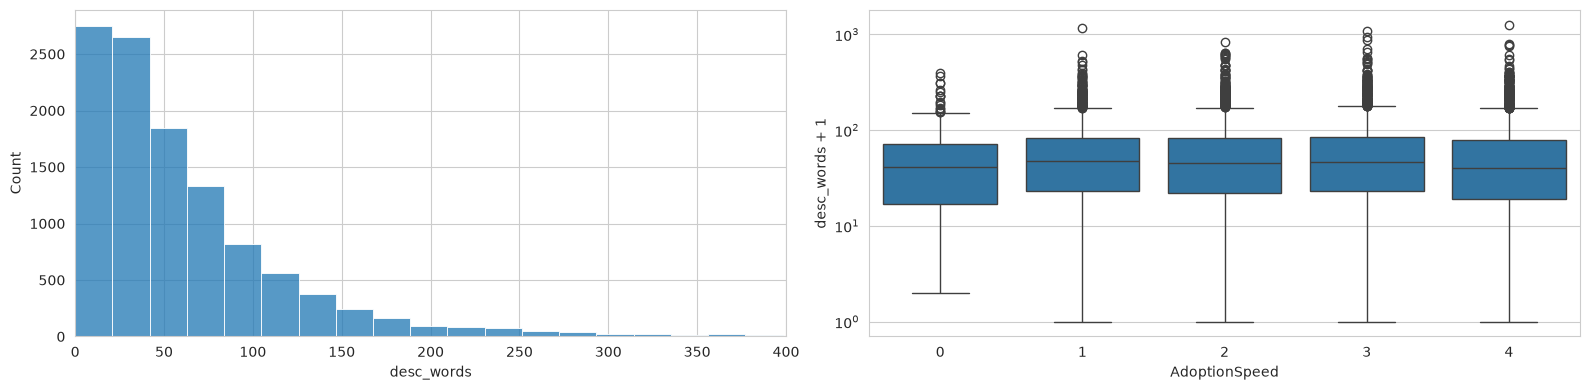

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(train['desc_words'], bins=60, ax=axes[0])
axes[0].set_xlim(0, 400)
sns.boxplot(x='AdoptionSpeed', y=train['desc_words'] + 1, data=train, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_ylabel('desc_words + 1')
plt.tight_layout()
pass

In [33]:
train.groupby('AdoptionSpeed')['desc_words'].median()

AdoptionSpeed
0    40.0
1    47.0
2    44.0
3    46.0
4    39.0
Name: desc_words, dtype: float64

Медиана 44 слова, но есть тексты больше 1000 слов. По классам разница небольшая: у класса 4 медиана 39 слов, у классов 1–3 от 44 до 47. Сама длина мало что даёт, а слова из описания извлечём через TF-IDF.

## Итоги

Быстрее пристраивают молодых животных, кошек, длинношёрстных, породистых и объявления с фото. Медленнее — взрослых собак-метисов, группы животных и объявления без фото. Плата и видео почти не влияют. Зависимости слабые и классы сильно перекрываются, поэтому высокой точности ждать не стоит.

# 4. Выбросы

Найдём выбросы в количественных признаках обучающей выборки двумя способами:

- правило 3σ: выброс, если значение отличается от среднего больше чем на 3 стандартных отклонения;
- правило IQR (как у ящика с усами): выброс, если значение меньше $Q_1 - 1.5\,IQR$ или больше $Q_3 + 1.5\,IQR$, где $IQR = Q_3 - Q_1$.

In [34]:
def outliers_3sigma(s):
    return (s - s.mean()).abs() > 3 * s.std()

def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

outl = pd.DataFrame({
    'Q1': [X_train[c].quantile(0.25) for c in numerical_columns],
    'Q3': [X_train[c].quantile(0.75) for c in numerical_columns],
    'max': [X_train[c].max() for c in numerical_columns],
    'выбросов 3σ': [outliers_3sigma(X_train[c]).sum() for c in numerical_columns],
    'выбросов IQR': [outliers_iqr(X_train[c]).sum() for c in numerical_columns],
}, index=numerical_columns)
outl

,Q1,Q3,max,выбросов 3σ,выбросов IQR
Age,2.0,12.0,255.0,287,1141
Quantity,1.0,1.0,20.0,174,2601
Fee,0.0,0.0,2000.0,304,1755
VideoAmt,0.0,0.0,8.0,119,433
PhotoAmt,2.0,5.0,30.0,212,691


In [35]:
rows_3s  = pd.concat([outliers_3sigma(X_train[c]) for c in numerical_columns], axis=1).any(axis=1)
rows_iqr = pd.concat([outliers_iqr(X_train[c]) for c in numerical_columns], axis=1).any(axis=1)
print(f'Строк с выбросом по 3σ:  {rows_3s.sum()} ({rows_3s.mean():.1%})')
print(f'Строк с выбросом по IQR: {rows_iqr.sum()} ({rows_iqr.mean():.1%})')

Строк с выбросом по 3σ:  1025 (9.1%)
Строк с выбросом по IQR: 5395 (48.0%)


По правилу 3σ выбросы есть в 9.1% строк, а по IQR в 48%.

Правило IQR не работает для `Fee`, `Quantity` и `VideoAmt`. У них больше 75% значений одинаковые (плата 0, одно животное, 0 видео), поэтому $Q_1 = Q_3$ и $IQR = 0$. Тогда выбросом считается любое значение, кроме самого частого: каждое платное объявление (1755, около 16%), каждое объявление о двух и более животных (2601, около 23%) и каждое объявление с видео. Это обычные значения, поэтому IQR здесь не подходит. Правило 3σ для скошенных распределений тоже не идеальное, но оно отмечает только редкие большие значения.

In [36]:
X_train.loc[outliers_3sigma(X_train['Age']), ['Type', 'Age', 'Breed1']].describe()

,Age
count,287.000000
mean,93.142857
std,28.574840
min,67.000000
25%,72.000000
50%,84.000000
75%,96.000000
max,255.000000


In [37]:
X_train.loc[X_train['Fee'] >= 1000, ['Type', 'Breed1', 'Fee', 'Quantity']].head(10)

,Type,Breed1,Fee,Quantity
4844,1,206,1000,1
10477,1,82,2000,1
8834,1,205,1000,1
2078,1,189,1000,1


По возрасту выбросы по 3σ — это 287 животных старше 66 месяцев (медиана 84 месяца, т.е. 7 лет). Это обычные взрослые животные. 255 месяцев (21 год) выглядит странно, но такое значение одно. Плата 1000–2000 ринггитов встречается у нескольких собак конкретных пород, скорее всего породистых, так что это тоже похоже на правду.

In [38]:
# Границы считаем только по обучающей выборке
low  = X_train[numerical_columns].quantile(0.005)
high = X_train[numerical_columns].quantile(0.995)
pd.DataFrame({'0.5%': low, '99.5%': high, 'max': X_train[numerical_columns].max()})

,0.5%,99.5%,max
Age,0.0,108.000,255.0
Quantity,1.0,9.000,20.0
Fee,0.0,500.000,2000.0
VideoAmt,0.0,2.000,8.0
PhotoAmt,0.0,23.785,30.0


In [39]:
log_columns = ['Age', 'Fee']

def treat_outliers(df):
    df = df.copy()
    df[numerical_columns] = df[numerical_columns].clip(lower=low, upper=high, axis=1)
    for c in log_columns:
        df[c] = np.log1p(df[c])
    return df

X_train = treat_outliers(X_train)
X_test  = treat_outliers(X_test)
X_train[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,11244.0,1.788607,1.020008,0.0,1.098612,1.386294,2.564949,4.691348
Quantity,11244.0,1.566169,1.328261,1.0,1.000000,1.000000,1.000000,9.000000
Fee,11244.0,0.679151,1.649824,0.0,0.000000,0.000000,0.000000,6.216606
VideoAmt,11244.0,0.049093,0.260491,0.0,0.000000,0.000000,0.000000,2.000000
PhotoAmt,11244.0,3.874844,3.392696,0.0,2.000000,3.000000,5.000000,23.785000


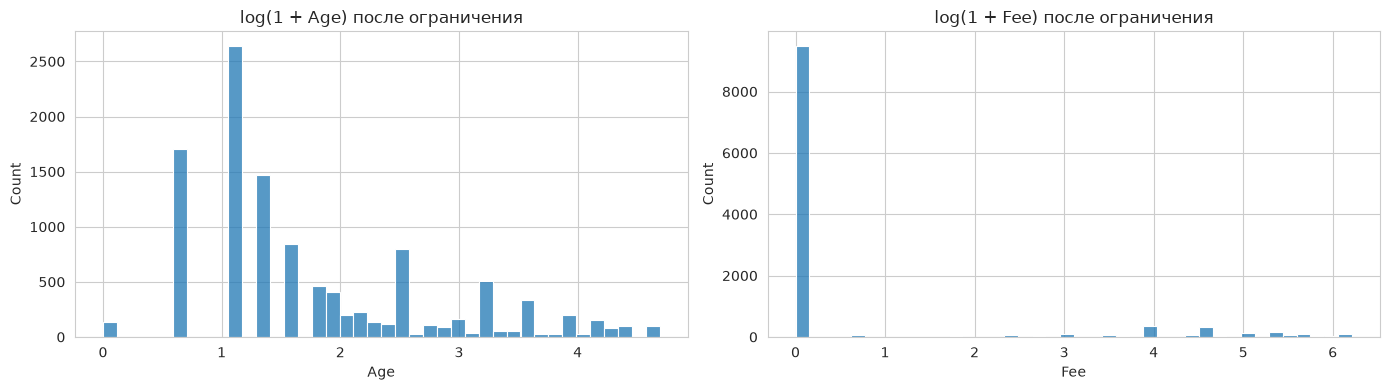

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, c in zip(axes, log_columns):
    sns.histplot(X_train[c], bins=40, ax=ax)
    ax.set_title(f'log(1 + {c}) после ограничения')
plt.tight_layout()
pass

Что делаем с выбросами. Значения в основном настоящие (старые животные, платные породистые, большие группы) и полезные: например, старых животных пристраивают хуже. Удалять 9% строк не хочется, а из тестовой выборки выбросы всё равно не удалишь, модель должна с ними работать. Поэтому:

1. ограничиваем (clip) количественные признаки квантилями 0.5% и 99.5%, посчитанными по train: возраст до 108 месяцев, `Quantity` до 9, `Fee` до 500, `VideoAmt` до 2, `PhotoAmt` до 23.8. Нижняя граница совпала с минимумом и ничего не меняет;
2. логарифмируем `Age` и `Fee` ($\log(1 + x)$), потому что разница между 1 и 12 месяцами важнее, чем между 100 и 111.

Строки не удаляем. После этого распределения `Age` и `Fee` стали менее скошенными. Деревьям это не важно, а для kNN и логистической регрессии полезно.

# 5. Пропущенные значения

## Кличка `Name`

Сама кличка не нужна, но может быть полезно, есть ли она: животное с кличкой, возможно, уже жило у людей. Проверим, нет ли кличек-заглушек, которые означают, что клички нет:

In [41]:
names = X_train['Name'].dropna().str.strip().str.lower()
no_name_pattern = r'no ?names?|unknown|unnamed|not yet|to be named|^nil$|^\W*$'
names[names.str.contains(no_name_pattern)].value_counts().head(20)

Name
no name                                  39
no name yet                              18
unknown                                  11
unnamed                                   5
no names yet                              4
not yet named                             2
nil                                       2
noname                                    2
(no name)                                 2
-                                         2
4 kittens open for adoption (no name)     1
unnamed.                                  1
no name yet (must neuter)                 1
- to be named -                           1
unknown 2                                 1
unnamed cats for adoption                 1
kitten (no name yet)                      1
(no names yet)                            1
no name for now                           1
lost kitten - unknown                     1
Name: count, dtype: int64

Заглушки есть: «No Name», «No Name Yet», «Unknown», «Unnamed», «Nil», «-» и т.п. Их тоже считаем отсутствием клички.

In [42]:
def add_has_name(df):
    df = df.copy()
    name = df['Name'].fillna('').str.strip().str.lower()
    df['has_name'] = ((name != '') & ~name.str.contains(no_name_pattern)).astype(int)
    return df.drop('Name', axis=1)

X_train = add_has_name(X_train)
X_test  = add_has_name(X_test)
X_train['has_name'].value_counts()

has_name
1    10189
0     1055
Name: count, dtype: int64

In [43]:
pd.Series(y_train).groupby(X_train['has_name']).mean().round(2)

has_name
0    2.59
1    2.51
Name: AdoptionSpeed, dtype: float64

Без клички 1055 животных в обучающей выборке (вместе с заглушками). Их пристраивают чуть медленнее, средний класс 2.59 против 2.51.

## Описание `Description`

Пропуск в описании значит, что описания нет. Заполним его пустой строкой, тогда длина описания будет 0, а TF-IDF-вектор нулевым.

In [44]:
X_train['Description'] = X_train['Description'].fillna('')
X_test['Description']  = X_test['Description'].fillna('')

print('Пропусков в train:', X_train.isnull().sum().sum())
print('Пропусков в test: ', X_test.isnull().sum().sum())

Пропусков в train: 0
Пропусков в test:  0


Пропусков не осталось.

# 6. Обработка категориальных признаков

## Бинарные признаки

`Type` принимает два значения (1 — собака, 2 — кошка), заменим его на `is_cat` со значениями 0/1. `has_name` уже бинарный.

У `Vaccinated`, `Dewormed`, `Sterilized` и `Gender` есть третье значение («не уверены» или «смешанная группа»), поэтому они не бинарные.

In [45]:
for df in (X_train, X_test):
    df['is_cat'] = (df['Type'] == 2).astype(int)
    df.drop('Type', axis=1, inplace=True)

binary_columns = ['is_cat', 'has_name']
X_train[binary_columns].mean().round(3)

is_cat      0.454
has_name    0.906
dtype: float64

## Породы

У `Breed1` 176 значений, и большинство встречаются всего несколько раз. Если сделать one-hot для всех пород, вместе с `Breed2` получится ~300 почти пустых столбцов. По породе, которая встретилась 2 раза, модель ничему не научится, а в kNN такие столбцы только добавят шум в расстояние. Поэтому оставим *N* самых частых пород (по обучающей выборке), а остальные объединим в «Other» (код `-1`).

In [46]:
breed1_counts = X_train['Breed1'].value_counts()
breed2_counts = X_train['Breed2'].value_counts()
print('Доля объявлений, покрытых топ-N пород Breed1:')
for n in [5, 10, 15, 20, 30]:
    print(f'  N = {n:2d}: {breed1_counts.head(n).sum() / len(X_train):.3f}')
print('Доля объявлений, покрытых топ-6 Breed2 (включая 0 = нет второй породы):',
      round(breed2_counts.head(6).sum() / len(X_train), 3))

Доля объявлений, покрытых топ-N пород Breed1:
  N =  5: 0.764
  N = 10: 0.833
  N = 15: 0.874
  N = 20: 0.902
  N = 30: 0.936
Доля объявлений, покрытых топ-6 Breed2 (включая 0 = нет второй породы): 0.911


In [47]:
TOP_BREED1, TOP_BREED2 = 10, 6
top_breed1 = breed1_counts.index[:TOP_BREED1]
top_breed2 = breed2_counts.index[:TOP_BREED2]

for df in (X_train, X_test):
    df['Breed1'] = df['Breed1'].astype(int).where(df['Breed1'].isin(top_breed1), -1).astype('category')
    df['Breed2'] = df['Breed2'].astype(int).where(df['Breed2'].isin(top_breed2), -1).astype('category')

print('Breed1:', sorted(X_train['Breed1'].unique()))
print('Breed2:', sorted(X_train['Breed2'].unique()))

Breed1: [-1, 141, 179, 205, 264, 265, 266, 285, 292, 299, 307]
Breed2: [-1, 0, 264, 265, 266, 299, 307]


10 самых частых пород покрывают 83% объявлений по `Breed1`, а 6 самых частых значений `Breed2` (вместе с 0, т.е. без второй породы) — 91%. Оставляем 10 пород в `Breed1` и 6 значений в `Breed2`, остальное в `-1`. Получается 18 one-hot столбцов вместо ~300.

## One-hot кодирование

Остальные категориальные признаки кодируем one-hot, как на лекции: признак с *s* значениями заменяем *s* столбцами из 0 и 1. Используем `OneHotEncoder`, он обучается на train и запоминает категории. С `handle_unknown='ignore'` значение, которого не было в train, в тесте закодируется нулями.

In [48]:
from sklearn.preprocessing import OneHotEncoder

onehot_columns = ['Breed1', 'Breed2', 'Gender', 'Color1', 'Color2', 'Color3',
                  'Vaccinated', 'Dewormed', 'Sterilized', 'State']

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(X_train[onehot_columns])

onehot_names = list(ohe.get_feature_names_out(onehot_columns))
print('Столбцов после one-hot:', len(onehot_names))

Столбцов после one-hot: 64


## Текстовый признак `Description`

Сначала добавим длину описания в словах и в символах. Распределение у них скошенное, как у `Age`, поэтому сразу логарифмируем.

In [49]:
for df in (X_train, X_test):
    df['desc_words'] = np.log1p(df['Description'].str.split().str.len())
    df['desc_chars'] = np.log1p(df['Description'].str.len())

text_len_columns = ['desc_words', 'desc_chars']

Теперь сам текст. Как в лекции про Corona NLP, переведём каждое описание в вектор TF-IDF. Для слова *t* в документе *d*

$$\text{TF-IDF}(t, d) = \text{TF}(t, d) \cdot \left(\log\frac{1 + N}{1 + \text{DF}(t)} + 1\right),$$

где TF — частота слова в документе, DF — число документов, в которых есть это слово, $N$ — число документов. Вес слова большой, если оно часто встречается в этом описании и редко в остальных. Параметры:

- `max_features=500`: берём 500 самых частых слов, иначе в словаре будут десятки тысяч слов;
- `min_df=5`: слово должно встретиться хотя бы в 5 описаниях;
- `stop_words='english'`: убираем служебные английские слова (the, and, is…), описания в основном на английском;
- `sublinear_tf=True`: вместо TF берём $1 + \log \text{TF}$, чтобы повторы одного слова не давали слишком большой вес.

Словарь строим по обучающей выборке.

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=500, min_df=5, stop_words='english', sublinear_tf=True)
tfidf.fit(X_train['Description'])

tfidf_names = ['w_' + w for w in tfidf.get_feature_names_out()]
T_train = tfidf.transform(X_train['Description']).toarray()
T_test  = tfidf.transform(X_test['Description']).toarray()
print(T_train.shape, T_test.shape)

(11244, 500) (3749, 500)


Сравним средний вес TF-IDF слов у быстро пристроенных (классы 0–1) и непристроенных (класс 4):

In [51]:
words = tfidf.get_feature_names_out()
fast = T_train[y_train.values <= 1].mean(axis=0)
slow = T_train[y_train.values == 4].mean(axis=0)
diff = pd.Series(fast - slow, index=words).sort_values()

print('Чаще у НЕ пристроенных (класс 4):\n', list(diff.index[:15]))
print('\nЧаще у быстро пристроенных (классы 0-1):\n', list(diff.index[::-1][:15]))

Чаще у НЕ пристроенных (класс 4):
 ['dog', 'friendly', 'dogs', 'good', 'need', 'contact', 'loving', 'whatsapp', 'guard', 'home', 'puppies', 'forever', 'spayed', 'smart', 'alert']

Чаще у быстро пристроенных (классы 0-1):
 ['adoption', 'kitten', 'puppy', 'male', 'mother', 'email', 'white', 'toilet', 'kittens', 'new', 'siblings', 'sms', 'kitty', 'adopted', 'interested']


У быстро пристроенных чаще встречаются kitten, kittens, puppy, kitty, mother, siblings, т.е. это котята и щенки, часто из одного помёта. У непристроенных чаще dog, dogs, guard (взрослые и сторожевые собаки) и слова вроде friendly, loving, forever, home. Получается, что в тексте есть информация о возрасте и виде животного, это совпадает с тем, что видели на графиках.

## Итоговая размерность

In [52]:
print('Количественные:    ', len(numerical_columns))
print('Порядковые:        ', len(ordinal_columns))
print('Длина описания:    ', len(text_len_columns))
print('Бинарные:          ', len(binary_columns))
print('One-hot:           ', len(onehot_names))
print('TF-IDF:            ', len(tfidf_names))
print('Всего:             ', len(numerical_columns) + len(ordinal_columns) + len(text_len_columns)
      + len(binary_columns) + len(onehot_names) + len(tfidf_names))

Количественные:     5
Порядковые:         3
Длина описания:     2
Бинарные:           2
One-hot:            64
TF-IDF:             500
Всего:              576


# 7. Нормализация

kNN ищет соседей по евклидову расстоянию. Если признаки в разных масштабах, расстояние почти полностью определяется признаком с самым большим разбросом. Например, `Fee` в исходных данных меняется от 0 до 3000, а бинарные признаки от 0 до 1, и разница в цене в 100 ринггитов весила бы в 100 раз больше, чем разница между кошкой и собакой. Поэтому количественные и порядковые признаки приводим к нулевому среднему и единичному стандартному отклонению (`StandardScaler`). Среднее и отклонение считаем по обучающей выборке и с ними же преобразуем тестовую.

Бинарные и one-hot признаки оставляем как есть, как на лекции. TF-IDF тоже не масштабируем: каждый вектор уже нормирован на длину 1, а если стандартизовать каждое слово отдельно, у редких слов станут слишком большие веса.

In [53]:
from sklearn.preprocessing import StandardScaler

scale_columns = numerical_columns + ordinal_columns + text_len_columns
scaler = StandardScaler()
scaler.fit(X_train[scale_columns])

print('Средние (train):', scaler.mean_.round(2))
print('Ст. отклонения (train):', scaler.scale_.round(2))

Средние (train): [1.79 1.57 0.68 0.05 3.87 1.86 1.47 1.04 3.68 5.34]
Ст. отклонения (train): [1.02 1.33 1.65 0.26 3.39 0.55 0.6  0.2  1.05 1.08]


Соберём все признаки в одну матрицу:

In [54]:
def build_matrix(df, T):
    return np.hstack([scaler.transform(df[scale_columns]),
                      df[binary_columns].values,
                      ohe.transform(df[onehot_columns]),
                      T])

feature_names = np.array(scale_columns + binary_columns + onehot_names + tfidf_names)
X_train_m = build_matrix(X_train, T_train)
X_test_m  = build_matrix(X_test, T_test)
y_train = y_train.values
y_test  = y_test.values

print(X_train_m.shape, X_test_m.shape)

(11244, 576) (3749, 576)


In [55]:
pd.DataFrame(X_train_m[:, :len(scale_columns)], columns=scale_columns).describe().loc[['mean', 'std']].round(3)

,Age,Quantity,Fee,VideoAmt,PhotoAmt,MaturitySize,FurLength,Health,desc_words,desc_chars
mean,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [56]:
pd.DataFrame(X_test_m[:, :len(scale_columns)], columns=scale_columns).describe().loc[['mean', 'std']].round(3)

,Age,Quantity,Fee,VideoAmt,PhotoAmt,MaturitySize,FurLength,Health,desc_words,desc_chars
mean,-0.018,-0.027,-0.002,-0.005,-0.001,0.003,-0.015,0.025,0.016,0.016
std,0.990,0.970,1.002,0.984,0.993,1.021,0.998,1.052,0.991,0.996


На обучающей выборке средние 0 и стандартные отклонения 1. На тестовой они близки к 0 и 1, но не равны, потому что параметры взяты из train.

# 8. Классификатор $k$NN

Метод $k$ ближайших соседей: для нового объявления находим $k$ ближайших объявлений из обучающей выборки и берём самый частый у них класс. Метод простой, был на лекции, не требует предположений о распределении данных, и у него один основной параметр $k$. С ним потом будем сравнивать остальные модели.

Сначала возьмём $k = 5$ (по умолчанию).

In [57]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_jobs=-1)
knn.fit(X_train_m, y_train)
knn

,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](5,)","[0,1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


# 9. Ошибки на обучающей и тестовой выборках

In [58]:
from sklearn.metrics import (accuracy_score, cohen_kappa_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

y_train_pred = knn.predict(X_train_m)
y_test_pred  = knn.predict(X_test_m)

acc_train = accuracy_score(y_train, y_train_pred)
acc_test  = accuracy_score(y_test, y_test_pred)
print(f'train: accuracy = {acc_train:.3f}, ошибка = {1 - acc_train:.3f}')
print(f'test:  accuracy = {acc_test:.3f}, ошибка = {1 - acc_test:.3f}')

train: accuracy = 0.564, ошибка = 0.436
test:  accuracy = 0.345, ошибка = 0.655


Точность на обучающей выборке 56.4%, на тестовой 34.5% (ошибка 65.5%). Разница большая, т.е. при $k = 5$ модель переобучается. На тесте kNN лишь немного лучше ответа «всегда 4» (28%).

## Матрицы рассогласования

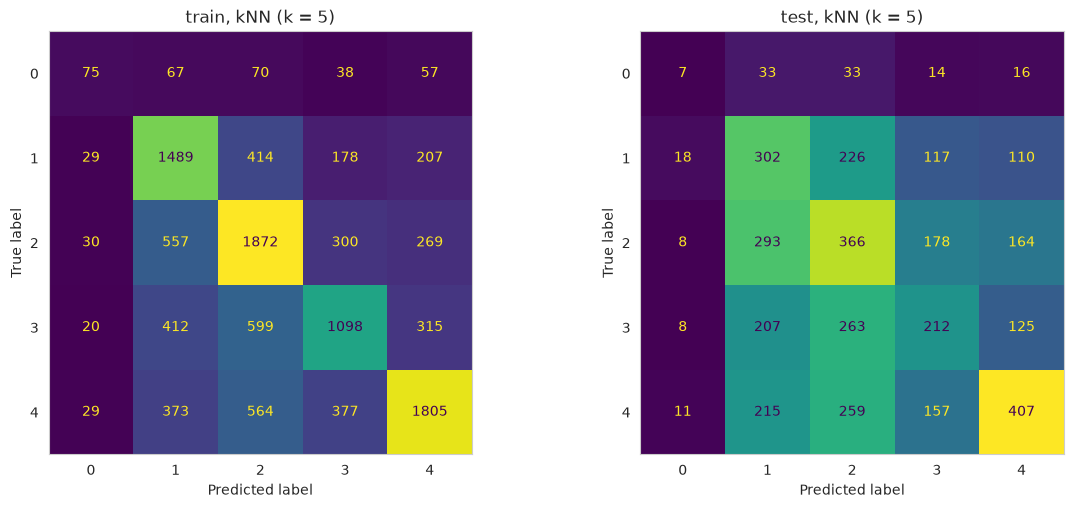

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axes[0], colorbar=False)
axes[0].set_title('train, kNN (k = 5)')
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=axes[1], colorbar=False)
axes[1].set_title('test, kNN (k = 5)')
for ax in axes:
    ax.grid(False)
pass

In [60]:
print(classification_report(y_test, y_test_pred, digits=3))

              precision    recall  f1-score   support

           0      0.135     0.068     0.090       103
           1      0.288     0.391     0.331       773
           2      0.319     0.363     0.340      1009
           3      0.313     0.260     0.284       815
           4      0.495     0.388     0.435      1049

    accuracy                          0.345      3749
   macro avg      0.310     0.294     0.296      3749
weighted avg      0.355     0.345     0.346      3749



На обучающей выборке диагональ выделяется сильно, на тестовой слабее. На тесте:

- класс 0 почти не угадывается: recall 0.068, т.е. 7 из 103. Класс редкий, и среди 5 соседей объекты класса 0 почти никогда не оказываются в большинстве;
- лучше всего угадывается класс 4 (recall 0.388, precision 0.495), он самый частый;
- много ошибок между соседними классами (2 и 1, 2 и 3), но есть и далёкие: 215 животных из класса 4 модель отнесла к классу 1.

## Квадратичная взвешенная каппа

Accuracy считает все ошибки одинаковыми. Но классы у нас упорядочены, и перепутать 3 и 4 не так плохо, как 0 и 4. В соревновании использовалась квадратичная взвешенная каппа Коэна (QWK):

$$\kappa = 1 - \frac{\sum_{i,j} w_{ij} O_{ij}}{\sum_{i,j} w_{ij} E_{ij}}, \qquad w_{ij} = \frac{(i - j)^2}{(K - 1)^2},$$

где $O$ — матрица рассогласования, $E$ — матрица, которая получилась бы при случайном угадывании с теми же частотами классов, $K = 5$. Штраф за ошибку растёт как квадрат расстояния между классами. $\kappa = 1$ при идеальном предсказании, $\kappa = 0$ — как случайное угадывание, $\kappa < 0$ — хуже случайного.

In [61]:
def qwk(y_true, y_pred):
    return cohen_kappa_score(y_true, y_pred, weights='quadratic')

print(f'QWK train: {qwk(y_train, y_train_pred):.3f}')
print(f'QWK test:  {qwk(y_test, y_test_pred):.3f}')

QWK train: 0.482
QWK test:  0.217


QWK на тесте 0.217, т.е. согласие слабое, но лучше случайного. На train 0.482, тоже видно переобучение.

## Подбор числа соседей $k$

Посмотрим, как ошибка на обучающей и тестовой выборках зависит от $k$:

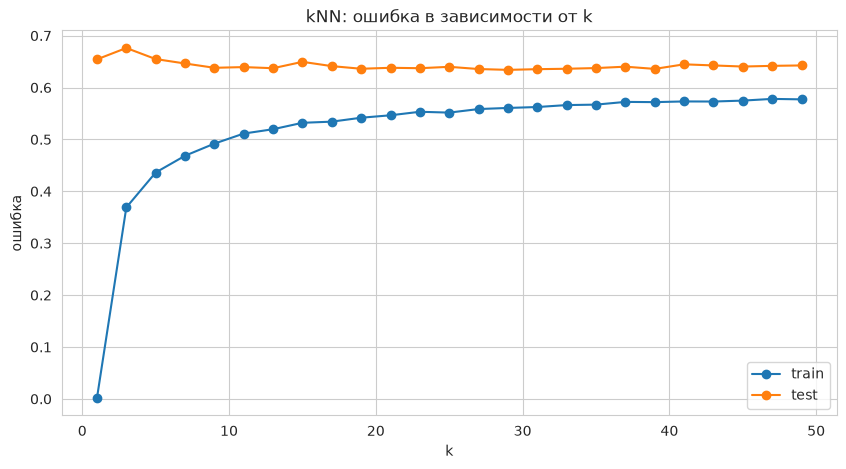

In [62]:
k_values = list(range(1, 51, 2))
err_train_k, err_test_k = [], []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(X_train_m, y_train)
    err_train_k.append(1 - accuracy_score(y_train, m.predict(X_train_m)))
    err_test_k.append(1 - accuracy_score(y_test, m.predict(X_test_m)))

plt.figure(figsize=(10, 5))
plt.plot(k_values, err_train_k, 'o-', label='train')
plt.plot(k_values, err_test_k, 'o-', label='test')
plt.xlabel('k')
plt.ylabel('ошибка')
plt.title('kNN: ошибка в зависимости от k')
plt.legend()
pass

In [63]:
k_best_test = k_values[int(np.argmin(err_test_k))]
print('k = 1: ошибка на train =', round(err_train_k[0], 4), ', на test =', round(err_test_k[0], 3))
print('Минимум ошибки на тесте при k =', k_best_test, ', ошибка =', round(min(err_test_k), 3))

k = 1: ошибка на train = 0.0017 , на test = 0.654
Минимум ошибки на тесте при k = 29 , ошибка = 0.634


При $k = 1$ ошибка на обучающей выборке почти нулевая (0.17%, не ноль из-за одинаковых объявлений с разными ответами), потому что ближайший сосед объекта — он сам. Это переобучение, на тесте ошибка при этом 65%. С ростом $k$ ошибка на train растёт до ~58%, а на тесте сначала падает и примерно с $k = 9$ держится на уровне 63–64%. При очень больших $k$ модель будет отвечать в основном самые частые классы, т.е. недообучаться. В нашем диапазоне ошибка на тесте почти не меняется, минимум 63.4% при $k = 29$.

Выбирать $k$ по тестовой выборке нельзя, иначе тест перестанет быть новыми данными. Подберём $k$ кросс-валидацией на обучающей выборке (`GridSearchCV`, как на лекции) с 5 блоками.

In [64]:
from sklearn.model_selection import GridSearchCV

nnb = [1, 3, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 60, 70]
grid = GridSearchCV(KNeighborsClassifier(), param_grid={'n_neighbors': nnb}, cv=5, n_jobs=-1)
grid.fit(X_train_m, y_train)

best_cv_err = 1 - grid.best_score_
best_n_neighbors = grid.best_params_['n_neighbors']
print('Лучшее k:', best_n_neighbors, ', ошибка на кросс-валидации:', round(best_cv_err, 3))

Лучшее k: 35 , ошибка на кросс-валидации: 0.626


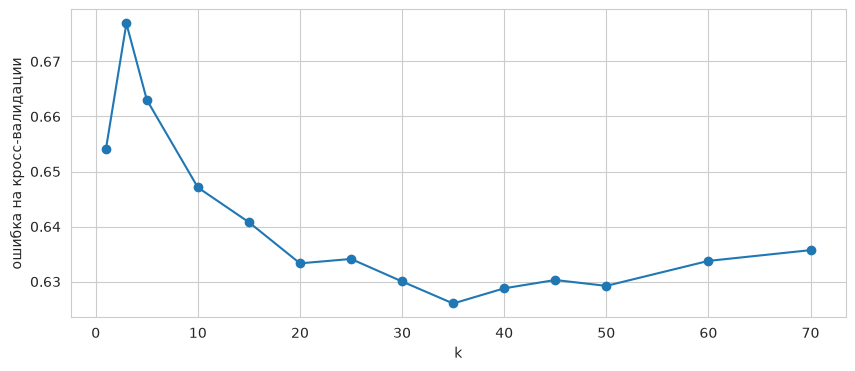

In [65]:
plt.figure(figsize=(10, 4))
plt.plot(nnb, 1 - grid.cv_results_['mean_test_score'], 'o-')
plt.xlabel('k')
plt.ylabel('ошибка на кросс-валидации')
pass

In [66]:
knn_best = KNeighborsClassifier(n_neighbors=best_n_neighbors, n_jobs=-1).fit(X_train_m, y_train)
y_train_pred = knn_best.predict(X_train_m)
y_test_pred  = knn_best.predict(X_test_m)

print(f'k = {best_n_neighbors}')
print(f'train: accuracy = {accuracy_score(y_train, y_train_pred):.3f}, ошибка = {1 - accuracy_score(y_train, y_train_pred):.3f}')
print(f'test:  accuracy = {accuracy_score(y_test, y_test_pred):.3f}, ошибка = {1 - accuracy_score(y_test, y_test_pred):.3f}')
print(f'QWK test: {qwk(y_test, y_test_pred):.3f}')

k = 35
train: accuracy = 0.433, ошибка = 0.567
test:  accuracy = 0.362, ошибка = 0.638
QWK test: 0.241


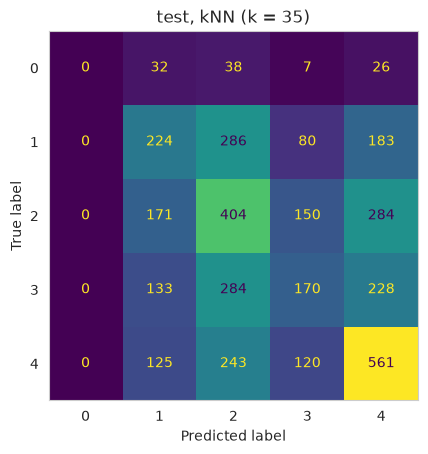

In [67]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, colorbar=False)
plt.title(f'test, kNN (k = {best_n_neighbors})')
plt.grid(False)
pass

Кросс-валидация выбрала $k = 35$ с ошибкой 62.6%. Это близко к минимуму на тестовой кривой ($k = 29$), но выбрано без теста. Accuracy на тесте выросла с 34.5% до 36.2%, QWK с 0.217 до 0.241, а точность на train (43.3%) стала ближе к тестовой, т.е. переобучение уменьшилось.

Класс 0 при $k = 35$ модель вообще не предсказывает (первый столбец матрицы нулевой), предсказания в основном 2 и 4.

Проверим, помогает ли kNN текст: обучим его с тем же $k$ без TF-IDF.

In [68]:
n_tab = X_train_m.shape[1] - len(tfidf_names)  # признаки без TF-IDF
knn_notext = KNeighborsClassifier(n_neighbors=best_n_neighbors, n_jobs=-1).fit(X_train_m[:, :n_tab], y_train)
p = knn_notext.predict(X_test_m[:, :n_tab])
print(f'kNN без TF-IDF: test accuracy = {accuracy_score(y_test, p):.3f}, QWK = {qwk(y_test, p):.3f}')

kNN без TF-IDF: test accuracy = 0.357, QWK = 0.230


Без TF-IDF результат почти такой же: 35.7% против 36.2%, QWK 0.230 против 0.241. Видимо, 500 TF-IDF координат с маленькими значениями мало влияют на евклидово расстояние по сравнению с остальными признаками.

# 10. Другие классификаторы

Результаты всех моделей будем складывать в таблицу:

In [69]:
results = []

def evaluate(model, name, Xtr=X_train_m, Xte=X_test_m):
    p_train, p_test = model.predict(Xtr), model.predict(Xte)
    res = {'метод': name,
           'accuracy train': accuracy_score(y_train, p_train),
           'accuracy test': accuracy_score(y_test, p_test),
           'QWK test': qwk(y_test, p_test)}
    print(f"{name}: train acc = {res['accuracy train']:.3f}, test acc = {res['accuracy test']:.3f}, "
          f"QWK test = {res['QWK test']:.3f}")
    return res, p_test

res, _ = evaluate(knn, 'kNN (k = 5)')
results.append(res)
res, _ = evaluate(knn_best, f'kNN (k = {best_n_neighbors})')
results.append(res)

kNN (k = 5): train acc = 0.564, test acc = 0.345, QWK test = 0.217


kNN (k = 35): train acc = 0.433, test acc = 0.362, QWK test = 0.241


## Логистическая регрессия

Для 5 классов строится мультиномиальная (softmax) регрессия. Параметр регуляризации `C` подберём кросс-валидацией.

In [70]:
from sklearn.linear_model import LogisticRegression

grid_lr = GridSearchCV(LogisticRegression(max_iter=5000),
                       param_grid={'C': [0.01, 0.1, 1]}, cv=3, n_jobs=-1)
grid_lr.fit(X_train_m, y_train)
best_C = grid_lr.best_params_['C']
print('Лучшее C:', best_C, ', ошибка на кросс-валидации:', round(1 - grid_lr.best_score_, 3))

lr = grid_lr.best_estimator_
res, _ = evaluate(lr, 'Логистическая регрессия')
results.append(res)

Лучшее C: 0.1 , ошибка на кросс-валидации: 0.606
Логистическая регрессия: train acc = 0.448, test acc = 0.384, QWK test = 0.295


С C = 0.1 получилось 38.4% на тесте и QWK 0.295, лучше kNN. На train точность 44.8%, разница с тестом небольшая, значит, модель почти не переобучается, но и нелинейные зависимости она не ловит.

## Случайный лес (Random Forest)

In [71]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train_m, y_train)
res, y_test_pred_rf = evaluate(rf, 'Random Forest')
results.append(res)

Random Forest: train acc = 0.998, test acc = 0.433, QWK test = 0.341


На train 99.8%, лес из глубоких деревьев почти полностью запоминает обучающую выборку. Но за счёт усреднения деревьев на тесте всё равно 43.3% и QWK 0.341, лучше предыдущих моделей.

### Значимость признаков

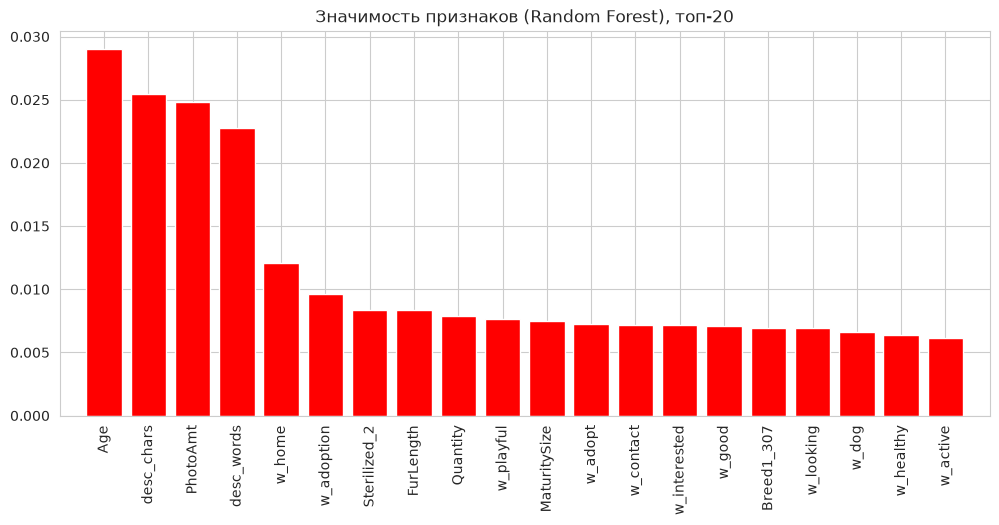

In [72]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

d_first = 20
plt.figure(figsize=(12, 5))
plt.title('Значимость признаков (Random Forest), топ-20')
plt.bar(range(d_first), importances[indices[:d_first]], align='center', color='r')
plt.xticks(range(d_first), feature_names[indices[:d_first]], rotation=90)
plt.xlim([-1, d_first])
pass

In [73]:
print('Суммарная значимость TF-IDF признаков:', round(importances[-len(tfidf_names):].sum(), 3))

Суммарная значимость TF-IDF признаков: 0.695


Самые важные признаки — возраст, длина описания (в символах и словах) и число фото. Дальше идут слова home и adoption, отсутствие стерилизации (`Sterilized_2`), длина шерсти, `Quantity`, размер и порода 307. Это примерно то же, что было видно на графиках. Каждое слово по отдельности весит мало, но в сумме на 500 признаков TF-IDF приходится 0.695 значимости. Правда, такая значимость (по уменьшению неоднородности) завышает роль признаков с большим числом разных значений, как у `Age` и длины описания.

## Экстремально случайные деревья (Extremely Randomized Trees)

В отличие от случайного леса, порог разбиения в каждой вершине выбирается случайно.

In [74]:
from sklearn.ensemble import ExtraTreesClassifier

ert = ExtraTreesClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
ert.fit(X_train_m, y_train)
res, _ = evaluate(ert, 'Extremely Randomized Trees')
results.append(res)

Extremely Randomized Trees: train acc = 0.998, test acc = 0.428, QWK test = 0.346


## Градиентный бустинг (Gradient Boosting)

Берём `HistGradientBoostingClassifier`, это быстрая реализация градиентного бустинга, в которой значения признаков разбиваются на интервалы. Обычный `GradientBoostingClassifier` на 570 признаках и 5 классах считался бы слишком долго. Параметры по умолчанию. Если в обучающей выборке больше 10 000 объектов, включается ранняя остановка по отложенной части train.

In [75]:
from sklearn.ensemble import HistGradientBoostingClassifier

gbt = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
gbt.fit(X_train_m, y_train)
print('Число итераций бустинга:', gbt.n_iter_)
res, _ = evaluate(gbt, 'Gradient Boosting (HGB)')
results.append(res)

Число итераций бустинга: 42
Gradient Boosting (HGB): train acc = 0.685, test acc = 0.400, QWK test = 0.319


## Машина опорных векторов (SVC)

SVC с гауссовым (RBF) ядром и параметрами по умолчанию. На всех 11 244 объектах он обучается около полутора-двух минут, поэтому параметры не подбираем.

In [76]:
from sklearn.svm import SVC

svc = SVC(random_state=RANDOM_STATE)
svc.fit(X_train_m, y_train)
res, _ = evaluate(svc, 'SVC (RBF)')
results.append(res)

SVC (RBF): train acc = 0.540, test acc = 0.383, QWK test = 0.299


## Сравнение

In [77]:
results_df = pd.DataFrame(results).set_index('метод')
results_df['ошибка test'] = 1 - results_df['accuracy test']
results_df.sort_values('QWK test', ascending=False).round(3)

,accuracy train,accuracy test,QWK test,ошибка test
метод,,,,
Extremely Randomized Trees,0.998,0.428,0.346,0.572
Random Forest,0.998,0.433,0.341,0.567
Gradient Boosting (HGB),0.685,0.400,0.319,0.600
SVC (RBF),0.540,0.383,0.299,0.617
Логистическая регрессия,0.448,0.384,0.295,0.616
kNN (k = 35),0.433,0.362,0.241,0.638
kNN (k = 5),0.564,0.345,0.217,0.655


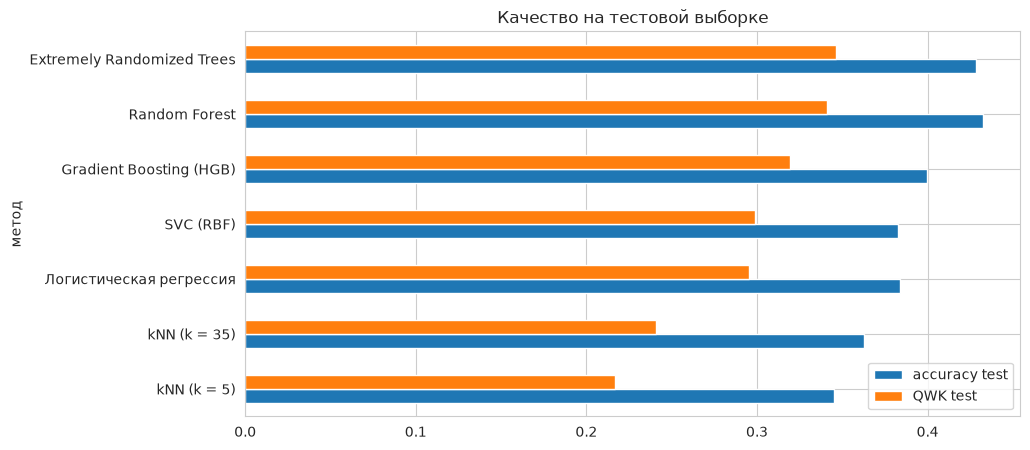

In [78]:
results_df[['accuracy test', 'QWK test']].sort_values('QWK test').plot(kind='barh', figsize=(10, 5))
plt.title('Качество на тестовой выборке')
pass

- Лучше всего ансамбли деревьев: Random Forest (43.3%, QWK 0.341) и Extremely Randomized Trees (42.8%, QWK 0.346). Разница между ними маленькая: по accuracy чуть лучше лес, по каппе ExtraTrees.
- Градиентный бустинг с параметрами по умолчанию дал 40.0% и QWK 0.319, он остановился после 42 итераций. Без подбора параметров он хуже леса.
- SVC и логистическая регрессия дают ~38% и QWK около 0.30.
- Хуже всех kNN (36.2%, QWK 0.241). Признаков 576, большинство из них разреженные one-hot и TF-IDF, и евклидово расстояние в таком пространстве плохо показывает, насколько объявления похожи.

У всех моделей, кроме логистической регрессии и kNN с большим $k$, точность на train заметно выше, чем на test. Даже лучшая модель ошибается почти в 57% случаев, потому что признаки слабо связаны с целевой переменной.

# 11. Несбалансированность классов

Класс 0 — всего 2.7% данных, и модели его почти не предсказывают. Попробуем два способа:

1. Веса классов (`class_weight='balanced'`): ошибка на объекте класса $c$ умножается на $\frac{N}{K \cdot N_c}$, т.е. ошибки на редком классе стоят дороже. Так можно у логистической регрессии, случайного леса и `HistGradientBoostingClassifier`.
2. Oversampling: копируем объекты класса 0 в обучающей выборке (случайный выбор с возвращением, `sklearn.utils.resample`). Это для kNN, у которого нет весов классов. Тестовую выборку не трогаем.

In [79]:
from sklearn.metrics import recall_score, f1_score

def short_metrics(y_pred):
    return {'accuracy test': accuracy_score(y_test, y_pred),
            'QWK test': qwk(y_test, y_pred),
            'recall класса 0': recall_score(y_test, y_pred, average=None)[0],
            'macro F1': f1_score(y_test, y_pred, average='macro')}

imb = []

In [80]:
lr_bal = LogisticRegression(C=best_C, max_iter=5000, class_weight='balanced').fit(X_train_m, y_train)
rf_bal = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE,
                                class_weight='balanced').fit(X_train_m, y_train)
gbt_bal = HistGradientBoostingClassifier(random_state=RANDOM_STATE,
                                         class_weight='balanced').fit(X_train_m, y_train)

for name, before, after in [('Логистическая регрессия', lr, lr_bal),
                            ('Random Forest', rf, rf_bal),
                            ('Gradient Boosting (HGB)', gbt, gbt_bal)]:
    imb.append({'метод': name, 'вариант': 'обычный', **short_metrics(before.predict(X_test_m))})
    imb.append({'метод': name, 'вариант': 'class_weight=balanced', **short_metrics(after.predict(X_test_m))})

In [81]:
from sklearn.utils import resample

idx0 = np.where(y_train == 0)[0]
n_target = np.bincount(y_train)[1:].min()  # доводим класс 0 до размера самого маленького из остальных
idx0_up = resample(idx0, replace=True, n_samples=n_target - len(idx0), random_state=RANDOM_STATE)
idx_over = np.concatenate([np.arange(len(y_train)), idx0_up])
X_over, y_over = X_train_m[idx_over], y_train[idx_over]

print('До:   ', np.bincount(y_train))
print('После:', np.bincount(y_over))

До:    [ 307 2317 3028 2444 3148]
После: [2317 2317 3028 2444 3148]


In [82]:
knn_over = KNeighborsClassifier(n_neighbors=best_n_neighbors, n_jobs=-1).fit(X_over, y_over)
imb.append({'метод': f'kNN (k = {best_n_neighbors})', 'вариант': 'обычный', **short_metrics(knn_best.predict(X_test_m))})
imb.append({'метод': f'kNN (k = {best_n_neighbors})', 'вариант': 'oversampling класса 0', **short_metrics(knn_over.predict(X_test_m))})

rf_over = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE).fit(X_over, y_over)
imb.append({'метод': 'Random Forest', 'вариант': 'oversampling класса 0', **short_metrics(rf_over.predict(X_test_m))})

imb_df = pd.DataFrame(imb).sort_values(['метод', 'вариант']).set_index(['метод', 'вариант'])
imb_df.round(3)

accuracy test  QWK test  \
метод                   вариант                                          
Gradient Boosting (HGB) class_weight=balanced          0.370     0.291   
                        обычный                        0.400     0.319   
Random Forest           class_weight=balanced          0.426     0.342   
                        oversampling класса 0          0.429     0.350   
                        обычный                        0.433     0.341   
kNN (k = 35)            oversampling класса 0          0.310     0.190   
                        обычный                        0.362     0.241   
Логистическая регрессия class_weight=balanced          0.333     0.260   
                        обычный                        0.384     0.295   

                                               recall класса 0  macro F1  
метод                   вариант                                           
Gradient Boosting (HGB) class_weight=balanced            0.262     0.324  
                        обычный                          0.107     0.341  
Random Forest           class_weight=balanced            0.155     0.374  
                        oversampling класса 0            0.126     0.361  
                        обычный                          0.107     0.359  
kNN (k = 35)            oversampling класса 0            0.301     0.273  
                        обычный                          0.000     0.280  
Логистическая регрессия class_weight=balanced            0.359     0.296  
                        обычный                          0.000     0.293

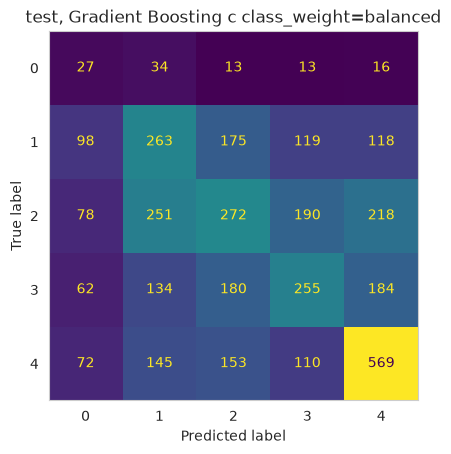

In [83]:
ConfusionMatrixDisplay.from_predictions(y_test, gbt_bal.predict(X_test_m), colorbar=False)
plt.title('test, Gradient Boosting с class_weight=balanced')
plt.grid(False)
pass

- Логистическая регрессия с весами: recall класса 0 вырос с 0 до 0.359, но accuracy упала с 38.4% до 33.3%, QWK с 0.295 до 0.260.
- kNN с oversampling: recall класса 0 вырос с 0 до 0.301, accuracy упала с 36.2% до 31.0%, QWK с 0.241 до 0.190.
- Градиентный бустинг: recall класса 0 вырос с 0.107 до 0.262, accuracy упала с 40.0% до 37.0%.
- Случайный лес почти не изменился: recall класса 0 стал 0.155 с весами и 0.126 с oversampling, accuracy почти та же. Глубокие деревья и так запоминают все объекты класса 0 из train, поэтому веса мало что меняют. С oversampling у леса каппа 0.350, чуть больше, чем было, но это в пределах разброса.

Модель начинает чаще отвечать 0 и находит часть объектов класса 0, но при этом ещё больше объектов других классов ошибочно относит к классу 0 (у бустинга это 98 объектов класса 1, 78 класса 2 и 72 класса 4). Класс 0 плохо отделяется от остальных, поэтому accuracy и каппа падают. Если нужно находить объявления, которые пристроят в тот же день, веса классов помогают. Если важна общая точность или каппа, лучше без балансировки.

# 12. Исключение коррелированных признаков

Найдём пары признаков (без TF-IDF) с $|\text{corr}| > 0.7$. Пары one-hot столбцов одного исходного признака (например, `Vaccinated_1` и `Vaccinated_2`) не учитываем, они связаны по построению.

In [84]:
tab_names = list(feature_names[:n_tab])
corr_tab = pd.DataFrame(X_train_m[:, :n_tab], columns=tab_names).corr()

def source(name):
    # имя исходного признака для one-hot столбца, например 'Vaccinated_3' -> 'Vaccinated'
    base = name.rsplit('_', 1)[0]
    return base if base in onehot_columns else name

pairs = []
for i, a in enumerate(tab_names):
    for b in tab_names[i + 1:]:
        if abs(corr_tab.loc[a, b]) > 0.7 and source(a) != source(b):
            pairs.append((a, b, round(corr_tab.loc[a, b], 3)))
pd.DataFrame(pairs, columns=['признак 1', 'признак 2', 'corr'])

,признак 1,признак 2,corr
0,Quantity,Gender_3,0.703
1,desc_words,desc_chars,0.990
2,is_cat,Breed1_307,-0.738
3,Vaccinated_3,Dewormed_3,0.843


Нашлось 4 пары:

- `desc_words` и `desc_chars` (0.99): длина в словах и в символах, по сути одно и то же;
- `Vaccinated_3` и `Dewormed_3` (0.84): если хозяин не знает про прививки, то обычно не знает и про глистов;
- `is_cat` и `Breed1_307` (−0.74): порода 307 бывает только у собак;
- `Quantity` и `Gender_3` (0.70): смешанная группа бывает только в объявлениях о нескольких животных.

Из каждой пары удалим второй признак. Ещё исходные `Vaccinated` и `Dewormed` коррелируют на 0.72 (пункт 3), поэтому удалим `Dewormed` целиком, со всеми его one-hot столбцами.

Зачем это нужно: коррелированные признаки дублируют информацию. В kNN такой признак по сути входит в расстояние дважды и получает лишний вес. В линейных моделях из-за мультиколлинеарности коэффициенты становятся неустойчивыми. И модель становится проще.

In [85]:
drop_features = [b for a, b, c in pairs]
# Vaccinated и Dewormed почти дублируют друг друга (corr исходных кодов 0.72, см. п. 3) - удаляем Dewormed целиком
drop_features += [n for n in tab_names if source(n) == 'Dewormed']
drop_features = sorted(set(drop_features))
print('Удаляем:', [str(f) for f in drop_features])

keep = ~np.isin(feature_names, drop_features)
X_train_r, X_test_r = X_train_m[:, keep], X_test_m[:, keep]
print('Признаков было:', X_train_m.shape[1], ', стало:', X_train_r.shape[1])

Удаляем: ['Breed1_307', 'Dewormed_1', 'Dewormed_2', 'Dewormed_3', 'Gender_3', 'desc_chars']
Признаков было: 576 , стало: 570


In [86]:
corr_res = []
for name, before, after_model in [
        (f'kNN (k = {best_n_neighbors})', knn_best, KNeighborsClassifier(n_neighbors=best_n_neighbors, n_jobs=-1)),
        ('Random Forest', rf, RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)),
        ('Логистическая регрессия', lr, LogisticRegression(C=best_C, max_iter=5000))]:
    after_model.fit(X_train_r, y_train)
    for variant, m, Xte in [('все признаки', before, X_test_m), ('без коррелированных', after_model, X_test_r)]:
        p = m.predict(Xte)
        corr_res.append({'метод': name, 'вариант': variant,
                         'accuracy test': accuracy_score(y_test, p), 'QWK test': qwk(y_test, p)})

pd.DataFrame(corr_res).set_index(['метод', 'вариант']).round(3)

accuracy test  QWK test
метод                   вариант                                     
kNN (k = 35)            все признаки                 0.362     0.241
                        без коррелированных          0.367     0.246
Random Forest           все признаки                 0.433     0.341
                        без коррелированных          0.424     0.308
Логистическая регрессия все признаки                 0.384     0.295
                        без коррелированных          0.381     0.274

- kNN почти не изменился: accuracy 36.2% → 36.7%, QWK 0.241 → 0.246. Стало чуть лучше, но разница в пределах разброса.
- Логистическая регрессия: accuracy 38.4% → 38.1%, QWK 0.295 → 0.274, немного хуже.
- Случайный лес стал хуже: accuracy 43.3% → 42.4%, QWK 0.341 → 0.308. Деревьям корреляция не мешает, а удалённые столбцы всё-таки несли информацию (порода 307 отделяет метисов от породистых собак, `Gender_3` отделяет группы от одиночных животных, корреляция 0.7 ещё не полное совпадение).

Для kNN удаление коррелированных признаков почти ничего не дало, а лесу навредило, поэтому для деревьев их лучше не удалять.

# 13. Выводы

### Данные

- 14 993 объявления о собаках и кошках из Малайзии. Классы `AdoptionSpeed` 1–4 встречаются примерно одинаково (21–28%), класс 0 редкий (2.7%).
- Больше всего на скорость пристройства влияют возраст (котят и щенков забирают быстрее), вид (кошек быстрее, чем собак), порода (беспородных собак медленнее), длина шерсти, число фото (без фото пристраивают хуже) и текст описания. Плата и видео почти не влияют.
- Стерилизованных и привитых животных пристраивают медленнее, но, скорее всего, потому, что они старше.
- Все зависимости слабые: корреляция любого признака с целевым по модулю не больше 0.11.

### Подготовка данных

- удалили `PetID` и `RescuerID`, разбили данные на train/test до подсчёта статистик, чтобы не было утечки;
- правило IQR не работает для `Fee` и `Quantity` ($Q_1 = Q_3$), поэтому строки не удаляли, а ограничили значения квантилями 0.5%/99.5% и прологарифмировали `Age` и `Fee`;
- кличку заменили на признак `has_name` (заглушки вроде «No Name» и «Unknown» считаются отсутствием клички), пустые описания на пустую строку;
- категориальные признаки закодировали one-hot, редкие породы объединили в «Other»;
- из описания сделали 500 признаков TF-IDF и длину описания, в случайном лесе на TF-IDF пришлась большая часть значимости;
- количественные признаки нормализовали (`StandardScaler` по train), для kNN это обязательно.

### Результаты

| Метод | accuracy test | QWK test |
|---|---|---|
| Random Forest | 0.433 | 0.341 |
| Extremely Randomized Trees | 0.428 | 0.346 |
| Gradient Boosting (HGB) | 0.400 | 0.319 |
| Логистическая регрессия | 0.384 | 0.295 |
| SVC (RBF) | 0.383 | 0.299 |
| kNN (k = 35) | 0.362 | 0.241 |
| kNN (k = 5) | 0.345 | 0.217 |

- kNN с $k = 5$ переобучается (56% на train, 35% на test). Кросс-валидация выбрала $k = 35$, на тесте 36.2%.
- Лучшие модели — Random Forest (точность 43.3%, ошибка 56.7%, QWK 0.341) и Extremely Randomized Trees (42.8%, QWK 0.346). Это примерно в 1.5 раза лучше ответа «всегда 4» (28%).
- С весами классов или oversampling модели находят часть объектов класса 0 (recall 0.30–0.36 у kNN и логистической регрессии), но accuracy и каппа падают.
- После удаления коррелированных признаков kNN почти не изменился (разница в пределах разброса), а случайный лес стал хуже, так что для деревьев удалять их не стоит.

### Почему точность невысокая

Точность около 40% для этих данных нормальная. Соседние классы трудно различить: животное, которое забрали на 7-й день, и животное, которое забрали на 8-й, попадают в разные классы. Скорость пристройства зависит и от того, чего нет в таблице: насколько животное симпатичное на фото, насколько активен приют, просто от случая. На Kaggle лучшие решения с изображениями и метаданными получили QWK около 0.45, у нас по таблице и тексту около 0.35.

### Что можно улучшить

- использовать изображения (признаки из предобученной нейросети) и метаданные фото, которые были в соревновании;
- взять эмбеддинги текста (word2vec, BERT) вместо TF-IDF и учесть, что часть описаний на малайском и китайском;
- добавить число объявлений у одного `RescuerID`, расшифровать коды пород и штатов (например, добавить население штата);
- подобрать параметры бустинга и леса, попробовать ансамбль моделей;
- учесть порядок классов: решать задачу как регрессию и подбирать пороги округления под QWK (так делали лучшие участники соревнования).